# Numerai Classic v6.0 ("Unity") — LightGBM Regressor (`NumeraiExtractions` + `LightGBMNumeraiEstimator`)

- **Data Loading (`data_utils.load_unity_numerai_data`)**: Resolves and downloads the Unity v6.0 Parquets using the official Kaggle clients (`kagglehub.dataset_download` and `kaggle.api.kaggle_api_extended.KaggleApi`) with `numerapi.NumerAPI` fallback, catching each library's actual exception classes (`KaggleApiHTTPError`, `UnauthenticatedError`, `CredentialError`, `NotFoundError`, `DataCorruptionError`, `BackendError`, `KaggleEnvironmentError`, `ColabEnvironmentError`, `kaggle.rest.ApiException`, `HTTPError`, `OSError`, `ValueError`).
- **Exploratory Data Analysis (`# EDA`)**: Lists available `TARGET_COL` and `feature_set` options from `features.json`, inspects `train_df.head(2)` / `validation_df.head(2)` and `info()`, plots era sizes over time (`groupby(ERA_COL)[TARGET_COL].size()`), overlays feature standard-deviation distributions across Train vs. Validation, and displays the top 10 features correlated with `TARGET_COL` along with ADF stationarity checks.

---

### 1. Feature Extraction Parameters (`utils.NumeraiExtractions` — `estimator__extractor__*`)
- **`era_col`** (`[ERA_COL]`): Column name containing the sequential weekly time index (`'era'`).
- **`ticker_col`** (`[TICKER_COL]`): Column name containing the security identifier (`'numerai_ticker'`).
- **`target_col`** (`[TARGET_COL, 'target_cyrusd_20', 'target_teager2b_20']`): Target column used when ranking features by target correlation.
- **`year_horizon_filter`** (`[None, (1, 2, 3), (4, 5, 6), (7, 8, 9)]`): Restricts `fit()` variance and correlation estimation to specific 52-week training year buckets `(era - 1) // 52 + 1` (`None` uses all training years; never exposed as a model feature).
- **`variance_threshold`** (`[None, 0.02, 0.05, 0.10]`): Drops near-constant features whose training variance is $\le$ threshold via `sklearn.feature_selection.VarianceThreshold` (`None` keeps all features).
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`):
  - `None`: Skips correlation ranking and keeps original column order.
  - `'pandas_mean'`: Computes per-era Pearson correlation (`era_df.corrwith(era_target)`) and averages across eras.
  - `'numerai_mean'`: Computes official per-era `numerai_tools.scoring.numerai_corr` and averages across eras.
  - `'pearson'`: Global pooled Pearson correlation (`r_regression`) across all rows.
  - `'spearman'`: Global pooled Spearman rank correlation across all rows.
- **`abs_corr`** (`[True, False]`): `True` ranks features by $|\text{corr}|$ (strongest magnitude in either direction); `False` ranks by signed $\text{corr}$ (positive only first).
- **`top_k`** (`[None, 10, 20, 40]`): Keeps only the top $K$ highest-ranked features from the extractor (`None` keeps all features).
- **`feature_selection_percentile`** (`[None, 25.0, 50.0, 75.0, 100.0]`): Keeps the top percentage of ranked features (`None` keeps all features).
- **`sparse_selector`** (`[None, 'lasso', 'elasticnet']`) & **`sparse_alpha`** (`[0.001, 0.01, 0.1]` / `Real(1e-4, 1e-1, prior='log-uniform')`): Optional multivariate sparse feature selection via `sklearn.feature_selection.SelectFromModel` with `Lasso` or `ElasticNet` fitted strictly inside `fit()` (`None` disables).
- **`pca_n_components`** (`[None, 10, 20, 40]` / `0.90`): Optional `sklearn.decomposition.PCA` compression fitted strictly inside `fit()` and quantized to `0..4` `int8` bins in `transform()` to reduce feature exposure without dropping features (`None` disables).
- **`quantize_scope`** (`['era', 'train_fit', 'global']`) & **`quantize_strategy`** (`['zscore', 'quantile']`): Controls how continuous derived features are quantized into `0..4` `int8` bins (`'era'` = leak-free within-era cross-sectional quantization; `'train_fit'` = frozen `StandardScaler` fitted strictly on training data in `fit()`; `'global'` = legacy full-array quantization; `'zscore'` = z-score rounding vs. `'quantile'` = `KBinsDiscretizer` quantile edges).
- **`sequence_top_n`** (`[4, 2, 8]`): Number of top-ranked features expanded by rolling-era, lag-diff, and per-ticker sequence extractors.
- **`missing_fill_value`** (`[2.0, 0.0, 4.0, 'mean', 'median', 'era_mean', 'era_median']`):
  - `2.0`, `0.0`, `4.0`, `'mean'`, `'median'`: Imputes missing values via `sklearn.impute.SimpleImputer` (`2.0` is the neutral middle bin of Numerai's `0..4` scale).
  - `'era_mean'` / `'era_median'`: Fills missing values with each feature's within-era cross-sectional mean or median.
- **`feature_groups`** (`unity_feature_groups` on `NumeraiExtractions`, `None` if no thematic groups exist in `feature_metadata['feature_sets']`; omitted from CV search spaces to prevent console log bloat) & **`basic_group_stats`** (`[None, 'mean', 'std', 'skew', 'mean|std', 'mean|skew', 'std|skew', 'mean|std|skew']`): Computes leak-free row-wise summary statistics (`mean`, `std`, `skew` quantized to `0..4` bins) across real Unity v6.0 feature groups or built-in thematic prefixes (`None` disables).
- **`fourier_period_eras`** (`[52, 26, 13]`): Cycle length in eras (52 = annual, 26 = semi-annual, 13 = quarterly) used by `fourier_order`.
- **`fourier_order`** (`[None, 1, 2, 3]`): Sole cyclical seasonality encoding — adds smooth $\sin(2\pi k \cdot \text{era} / P)$ and $\cos(2\pi k \cdot \text{era} / P)$ harmonics for $k=1..\text{fourier\_order}$ quantized to `0..4` bins (`None` disables).
- **`include_rolling_era`** (`[False, True]`) & **`rolling_era_windows`** (`[(4, 12), (2, 6, 12), (4, 8, 16)]`): When `include_rolling_era=True`, computes causal rolling era means over each window length $W$ in `rolling_era_windows` for the top correlated features, quantized to `0..4` bins.
- **`include_lag_diff`** (`[False, True]`) & **`era_lag_scales`** (`[(1, 2, 4), (1, 2, 4, 8), (2, 4, 8)]`): When `include_lag_diff=True`, computes causal era-to-era lag differences ($\bar{x}_e - \bar{x}_{e-k}$) for each lag step $k$ in `era_lag_scales`, quantized to `0..4` bins.
- **`ticker_features`** (`[None, 'rolling_mean', 'momentum_diff', 'weeks_since_high', 'rolling_rank', 'weeks_since_change', 'expanding_stats', 'raw_lags', 'rolling_mean|momentum_diff', 'rolling_mean|momentum_diff|rolling_rank', 'expanding_stats|raw_lags', 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags']`), **`ticker_windows`** (`[(4, 12), (2, 6, 12)]`), & **`ticker_lag_steps`** (`[None, (1, 2), (1, 2, 4)]`): Computes causal per-ticker time-series features grouped strictly by `numerai_ticker` sorted chronologically by `era` (`None` disables).
- **`era_dispersion_features`** (`[None, 'mean', 'std', 'extreme_frac', 'mean|std', 'mean|extreme_frac', 'std|extreme_frac', 'mean|std|extreme_frac']`): Adds per-row cross-sectional mean (`'mean'`), standard deviation (`'std'`), and fraction of extreme `0`/`4` bins (`'extreme_frac'`) across selected features (`None` disables).

---

### 2. Shared Parent Estimator Parameters (`baseline_utils.BaseNumeraiEstimator` — `estimator__*`)
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`): How the estimator scores post-extraction features against `TARGET_COL` (used when `top_k` is set).
- **`abs_corr`** (`[True, False]`): `True` selects top features by $|\text{corr}|$; `False` selects by signed $\text{corr}$.
- **`top_k`** (`[None, 20, 40, 80]`): Number of top post-extraction features passed to LightGBM (`None` uses all extracted features).
- **`era_weighting`** (`[None, 'equal_era', 'recency_linear', 'recency_exp']`): Computes per-row `sample_weight` passed into `LGBMRegressor.fit(...)` (`None`, equal weight per era, linear recency, or exponential recency decay).
- **`recency_decay`** (`Real(0.001, 0.020)`): Exponential decay rate per era when `era_weighting='recency_exp'`.
- **`prediction_transform`** (`[None, 'era_zscore', 'era_rank']`): Post-prediction within-era normalization (`None` = raw, `'era_zscore'`, or `'era_rank'`).
- **`bias_correction`** (`[None, 'mean_residual']`): When `'mean_residual'`, records `mean(y_train - y_hat_train)` in `fit()` and adds it to predictions in `predict()` (`None` disables).

---

### 3. LightGBM Model Parameters (`lgbm_utils.LightGBMNumeraiEstimator` — `estimator__*`)
- **Boosting & Objective**:
  - **`boosting_type`** (`['gbdt', 'dart', 'rf']`): Gradient boosting decision trees, Dropouts meet Multiple Additive Regression Trees, or Random Forest.
  - **`objective`** (`['regression', 'regression_l1', 'huber', 'fair', 'quantile']`): Loss function (`'regression'` = L2/MSE, `'regression_l1'` = L1/MAE, `'huber'`, `'fair'`, `'quantile'`).
  - **`alpha`** (`[0.9, 0.5, 1.0]` / `Real(0.1, 2.0)`): Huber loss delta or Quantile loss $\alpha$ when `objective` is `'huber'` or `'quantile'`.
  - **`fair_c`** (`[1.0, 0.5, 2.0]` / `Real(0.1, 5.0)`): Scale parameter $c$ when `objective='fair'`.
- **Tree Structure & Learning Schedule**:
  - **`n_estimators`** (`[200, 100, 500, 1000, 2000]` / `Integer(50, 2000)`): Number of boosting rounds (trees).
  - **`learning_rate`** (`[0.05, 0.01, 0.03, 0.1]` / `Real(0.005, 0.15, prior='log-uniform')`): Shrinkage rate per boosting iteration.
  - **`num_leaves`** (`[31, 15, 63, 127]` / `Integer(7, 128)`): Maximum tree leaves for base learners (auto-clamped to $2^{\text{max\_depth}}$ when `max_depth > 0`).
  - **`max_depth`** (`[5, -1, 3, 4, 6, 8]` / `Integer(2, 10)`): Maximum tree depth (`-1` = unlimited).
  - **`extra_trees`** (`[False, True]`): Extremely randomized threshold selection per feature to reduce overfitting.
  - **`linear_tree`** (`[False, True]`) & **`linear_lambda`** (`[0.0, 0.01, 0.1, 1.0]` / `Real(0.0, 5.0)`): Fits piecewise linear models at tree leaves with L2 penalty `linear_lambda`.
- **Leaf Constraints & Regularization**:
  - **`min_split_gain`** (`[0.0, 0.001, 0.01, 0.1]` / `Real(0.0, 0.5)`): Minimum loss reduction required to make a split.
  - **`min_child_weight`** (`[1e-3, 1e-2, 1.0, 10.0]` / `Real(1e-4, 10.0, prior='log-uniform')`): Minimum sum of instance hessian in a leaf.
  - **`min_child_samples`** (`[20, 50, 100, 200]` / `Integer(10, 300)`): Minimum number of rows needed in a leaf (`min_data_in_leaf`).
  - **`reg_alpha`** (`[0.0, 0.01, 0.1, 1.0, 10.0]` / `Real(0.0, 10.0)`): L1 regularization term on leaf weights.
  - **`reg_lambda`** (`[0.0, 0.01, 0.1, 1.0, 10.0]` / `Real(0.0, 10.0)`): L2 regularization term on leaf weights.
  - **`path_smooth`** (`[0.0, 1.0, 10.0, 50.0]` / `Real(0.0, 50.0)`): Hierarchical leaf smoothing toward parent node predictions.
  - **`max_delta_step`** (`[0.0, 0.5, 1.0]` / `Real(0.0, 2.0)`): Limits maximum leaf output magnitude (`0.0` = no constraint).
- **Subsampling & Feature Fraction**:
  - **`subsample`** (`[1.0, 0.8, 0.6]` / `Real(0.5, 1.0)`): Row bagging fraction (`bagging_fraction`).
  - **`subsample_freq`** (`[0, 1, 5]` / `Integer(0, 5)`): Frequency of row bagging (`0` disables; auto-enforced $\ge 1$ for `boosting_type='rf'`).
  - **`colsample_bytree`** (`[0.1, 0.25, 0.5, 0.8, 1.0]` / `Real(0.05, 1.0)`): Fraction of features randomly chosen per tree (`feature_fraction`).
  - **`colsample_bynode`** (`[1.0, 0.5, 0.8]` / `Real(0.3, 1.0)`): Fraction of features randomly chosen at each split node (`feature_fraction_bynode`).
- **Histogram Binning**:
  - **`max_bin`** (`[255, 5, 15, 63]` / `Categorical([5, 15, 63, 255])`): Maximum number of bins for feature bucketing (`5` matches Numerai's native `0..4` int8 bins).
  - **`min_data_in_bin`** (`[3, 5, 10]` / `Integer(1, 20)`): Minimum number of rows inside one histogram bin.
  - **`subsample_for_bin`** (`[200000, 50000, 500000]`): Number of samples used to construct histogram bins.
- **DART Parameters** (active when `boosting_type='dart'`):
  - **`drop_rate`** (`[0.1, 0.05, 0.2]` / `Real(0.01, 0.3)`), **`max_drop`** (`[50, 20, 100]` / `Integer(10, 100)`), **`skip_drop`** (`[0.5, 0.3, 0.7]` / `Real(0.1, 0.9)`), **`xgboost_dart_mode`** (`[False, True]`), **`uniform_drop`** (`[False, True]`).
- **System & Diagnostics**:
  - **`importance_type`** (`['gain', 'split']`), **`feature_pre_filter`** (`[True, False]`), **`force_col_wise`** (`[False, True]`), **`force_row_wise`** (`[False, True]`), **`n_jobs`** (`[lgbm_n_jobs]`), **`lgbm_verbosity`** (`[-1]`).

---

- **Evaluation (`utils.evaluate_numerai_predictions`)**: Reports official `numerai_tools.scoring.numerai_corr`, per-era `Spearman Correlation`, `Average Payout` (`(corrs / 0.2).clip(-1, 1)`), `Sharpe Ratio` (`corrs.mean() / corrs.std()`), `Mean Absolute Error (MAE)`, `Forecast Bias` (`mean(y_true - y_pred)`), `Directional Hit Rate` (sign agreement vs. `0.5`), `Era CORR Lag-1 ACF`, `Ljung-Box p-value` (`acorr_ljungbox`), `ARCH-LM p-value` (`het_arch`), `ADF Stationarity p-value` (`adfuller`), `Skewness`, `Excess Kurtosis`, `Jarque-Bera p-value`, `Max Drawdown`, and validation `Feature Exposure`.

In [1]:
import gc
import os
import sys
import json
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

python_env_dir = Path(sys.executable).parent
library_bin_dir = python_env_dir / 'Library' / 'bin'
if library_bin_dir.is_dir() and str(library_bin_dir) not in os.environ.get('PATH', ''):
    os.environ['PATH'] = str(library_bin_dir) + os.pathsep + str(python_env_dir) + os.pathsep + os.environ.get('PATH', '')

import numpy as np
import pandas as pd
import lightgbm as lgb
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
try:
    import seaborn as sns
except ImportError:
    sns = None
from IPython.display import display

warnings.filterwarnings('ignore')

# Local, Kaggle (/kaggle/input, /kaggle/usr/lib, /kaggle/working), & nested dataset path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
if workspace_root not in sys.path:
    sys.path.insert(0, workspace_root)
if os.path.isdir(src_path) and src_path not in sys.path:
    sys.path.insert(0, src_path)

module_search_roots = [
    Path(workspace_root),
    Path('/kaggle/working'),
    Path('/kaggle/usr/lib'),
    Path('/kaggle/input'),
]
for search_root in module_search_roots:
    if not search_root.is_dir():
        continue
    for target_file in ('afml_utils.py', 'data_utils.py', 'utils.py', 'baseline_utils.py', 'lgbm_utils.py'):
        for found_path in search_root.rglob(target_file):
            parent_dir = str(found_path.parent)
            if parent_dir not in sys.path:
                sys.path.insert(0, parent_dir)

from pandas.plotting import autocorrelation_plot
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from statsmodels.graphics.gofplots import qqplot

from numerai_tools.scoring import numerai_corr

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

try:
    import wandb
except ImportError:
    wandb = None

try:
    import afml_utils
    import data_utils
    import utils
    import baseline_utils
    import lgbm_utils
except ModuleNotFoundError as import_err:
    mounted_kaggle_inputs = [str(p) for p in sorted(Path('/kaggle/input').iterdir())] if Path('/kaggle/input').is_dir() else []
    raise ModuleNotFoundError(
        f"{import_err}. Could not locate data_utils.py / utils.py / baseline_utils.py / lgbm_utils.py in "
        f"workspace_root={workspace_root}, /kaggle/working, /kaggle/usr/lib, or /kaggle/input "
        f"(mounted inputs: {mounted_kaggle_inputs}). "
        "On Kaggle, attach a Dataset or Utility Script containing src/data_utils.py, src/utils.py, src/baseline_utils.py, and src/lgbm_utils.py."
    ) from import_err
importlib.reload(afml_utils)
importlib.reload(data_utils)
importlib.reload(utils)
importlib.reload(baseline_utils)
importlib.reload(lgbm_utils)
from data_utils import (
    compute_per_ticker_timeseries_features,
    discover_and_fetch_v6_meta_or_benchmark,
    load_unity_numerai_data,
    load_unity_numerai_data_cached,
)
from utils import (
    NumeraiExtractions,
    build_experiment_setup,
    build_conditional_bayesian_spaces,
    build_quick_results_df,
    candidate_score,
    compute_eda_era_stationarity,
    compute_era_error_envelope,
    configure_error_binning,
    compute_feature_exposure,
    compute_feature_target_correlations,
    compute_per_era_numerai_corr,
    compute_per_era_spearman_corr,
    deduplicate_param_grid,
    drop_constant_dims,
    evaluate_numerai_predictions,
    export_diagnostics_predictions,
    plot_era_error_envelope,
    plot_residual_diagnostics,
    prepare_bayesian_space,
    prepare_tuned_pipeline,
    quantize_to_5bins,
    reset_cv_metric_log,
    sharpe_ratio,
    build_live_staking_scenarios_df,
    compute_deflated_sharpe_ratio,
    compute_per_era_mmc,
    compute_probabilistic_sharpe_ratio,
    plot_stake_pnl_dashboard,
    plot_stake_pnl_monte_carlo,
    run_numereval_diagnostics,
    simulate_live_staking_scenarios,
    simulate_stake_pnl,
    simulate_stake_pnl_monte_carlo,
    walk_forward_predict,
    CombinatorialPurgedEraCV,
    PurgedEraKFold,
    build_era_cv_splits,
    compute_clustered_mda,
    compute_drawdown_and_tuw,
    compute_hhi_concentration,
    compute_lo_adjusted_sharpe,
    compute_min_track_record_length,
    compute_pbo_cscv,
    compute_per_era_fnc,
    compute_r1399_churn_retention,
    compute_strategy_risk,
    compute_versioned_candidate_score,
    make_candidate_scorer,
    neutralize_predictions,
    purge_train_before_validation,
    summarize_afml_backtest_diagnostics,
    build_compact_afml_reference_table,
    build_diagnostics_summary_table,
    build_executive_scorecard_tables,
    display_compact_dataframe,
    export_winner_scorecard_json,
    plot_afml_backtest_story,
    plot_cumulative_validation_corr,
    plot_rolling_validation_corr,
    plot_top2_residuals_vs_actual,
    build_afml_diagnostics_df,
    strip_validation_predictions,
)
from baseline_utils import (
    BaseNumeraiEstimator,
    clear_extraction_cache,
    configure_extraction_cache,
    display_top_cv_candidates,
    extract_cv_analysis_artifacts,
)
from lgbm_utils import (
    LightGBMNumeraiEstimator,
    clear_lgb_dataset_cache,
    display_lgbm_interpretability,
    extract_lgbm_interpretability,
)

print('Imports loaded successfully')
print(f'workspace_root={workspace_root} | LightGBM={lgb.__version__} | SKOPT_AVAILABLE={SKOPT_AVAILABLE}')

Imports loaded successfully
workspace_root=/kaggle/working | LightGBM=4.6.0 | SKOPT_AVAILABLE=True


# Setup

In [2]:
# --- Experiment Knobs (only things you actually change) ---
TARGET_COL = 'target'          # Training target (auto-sets horizon & embargo)
feature_set = 'all'          # 'small', 'medium', or 'all'
era_stride = 'auto'            # 'auto' (matches target horizon: 12 for 60d, 4 for 20d) or explicit int (1, 2, 4, 12)

search_mode = 'bayes'          # 'grid' or 'bayes'
score_version = 'v1_skepta'    # 'v0_default', 'v1_skepta', or 'v2_skepta_mmc'
eval_mode = 'both'             # 'static', 'walk_forward', or 'both'
cv_strategy = 'timeseries'   # 'timeseries', 'purged_kfold' (AFML Ch. 7), or 'cpcv' (AFML Ch. 12)
n_splits = 1
cv_split = 0.8                 # Chronological CV train/test split ratio (used when n_splits == 1)
downsample_mode = 'recent'  # None, 'recent', 'earliest', or 'uniform'
downsample_frac = 1.0          # Fraction of strided training data to keep in (0.0, 1.0]
val_downsample_mode = 'recent'     # Validation: None (100%), 'same', 'recent', 'earliest', or 'uniform'
val_downsample_frac = 1.0             # Fraction of validation data to keep in (0.0, 1.0] (None mirrors downsample_frac)
n_iter = 5
n_jobs = -1                    # LightGBM thread count (inner CV stays 1 to avoid RAM duplication)
save_results = True
error_bin_mode = 'pct'         # 'pct' (% error + zero-target tol) or 'abs' (raw residual bins)

setup_cfg = build_experiment_setup(
    target_col=TARGET_COL,
    feature_set=feature_set,
    era_stride=era_stride,
    model_tag='lightgbm',
    search_mode=search_mode,
    score_version=score_version,
    eval_mode=eval_mode,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    n_iter=n_iter,
    n_jobs=1,
    lgbm_n_jobs=n_jobs,
    save_results=save_results,
    error_bin_mode=error_bin_mode,
    workspace_root=workspace_root,
)
globals().update(setup_cfg)

Experiment: numerai_v6.0_all_eras_stride12_lightgbm | model=lightgbm | search_mode=bayes | cv_strategy=timeseries (cv_split=0.8) | ERA_COL=era | TARGET_COL=target | era_stride=12 (auto-matched to horizon=12) | horizon=12 | embargo=1


# Prep

In [3]:
_prep_t0 = time.perf_counter()
train_df, validation_df, feature_columns, feature_metadata = load_unity_numerai_data_cached(
    data_version=data_version,
    data_folder=data_folder,
    kaggle_dataset=kaggle_dataset,
    feature_set=feature_set,
    target_col=TARGET_COL,
    era_stride=era_stride,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    random_state=random_state,
    ticker_timeseries_features=ticker_timeseries_features,
    ticker_rolling_windows=ticker_rolling_windows,
    ticker_lag_steps=ticker_lag_steps,
    workspace_root=workspace_root,
    auto_download=True,
    use_numerapi_fallback=True,
    force_reload=force_reload_data_cache,
)
prep_elapsed_s = time.perf_counter() - _prep_t0
print(f'Loaded {len(feature_columns)} int8 features | train={train_df.shape} ({train_df[ERA_COL].nunique()} eras) | validation={validation_df.shape} ({validation_df[ERA_COL].nunique()} eras)')

Loaded 1040 int8 features | train=(361584, 1045) (70 eras) | validation=(2660746, 1045) (399 eras)


## Exploratory Data Analysis (EDA)

In [4]:
available_targets = list(feature_metadata.get('targets', [TARGET_COL]))
print(f'Available TARGET_COL options ({len(available_targets)}):', available_targets)
print('Available feature_set options:', {k: len(v) for k, v in feature_metadata.get('feature_sets', {}).items()})

print('\nTraining data:')
display(train_df.head(2))
print('Validation data:')
display(validation_df.head(2))
print('Training set info:')
train_df.info()
print('\nValidation set info:')
validation_df.info()

Available TARGET_COL options (24): ['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
Available feature_set options: {'small': 101, 'medium': 351, 'all': 1040, 'signals': 23}

Training data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
0,2003-01-03,train,000270 KR,2,2,2,0,0,0,3,...,2,2,2,2,2,0,2,2,0.50,1
1,2003-01-03,train,000810 KR,2,2,2,2,2,2,2,...,2,2,2,2,2,0,2,2,0.25,1


Validation data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
0,2019-01-04,validation,000030 KR,2,2,2,1,1,1,0,...,0,0,1,1,1,2,0,2,0.5,836
1,2019-01-04,validation,000060 KR,2,2,2,4,4,3,2,...,1,2,2,0,2,1,0,2,0.5,836


Training set info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361584 entries, 0 to 361583
Columns: 1045 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(1040), object(2)
memory usage: 369.7+ MB

Validation set info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2660746 entries, 0 to 2660745
Columns: 1045 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(1040), object(2)
memory usage: 2.7+ GB


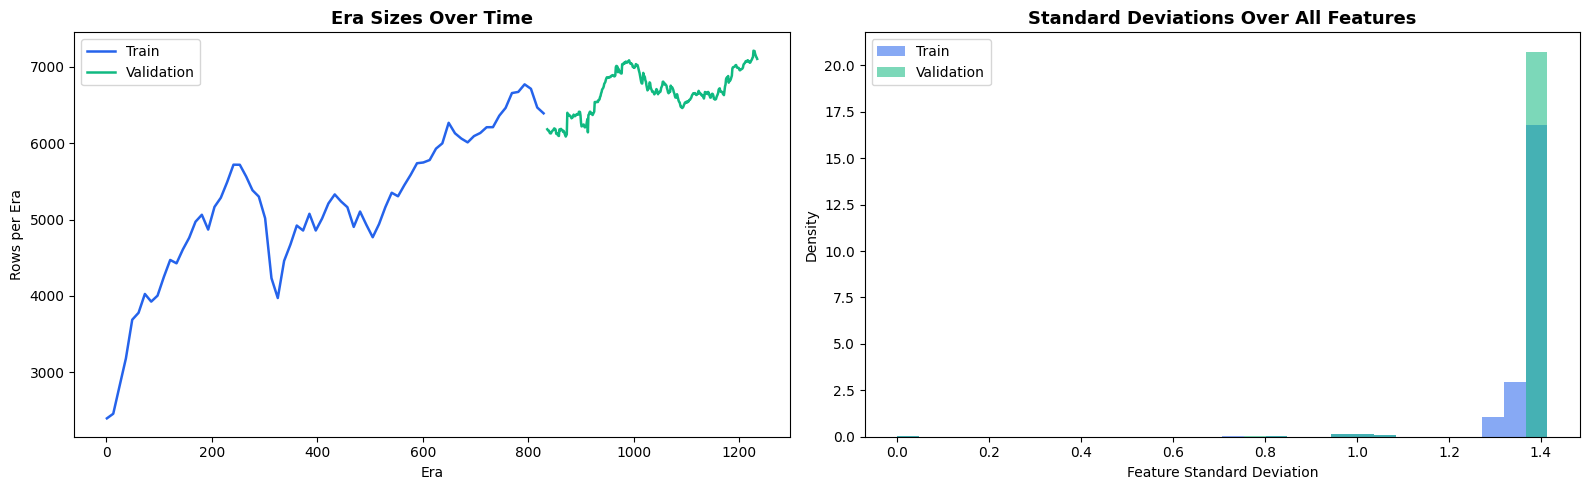

Top 10 Features according to absolute correlation with target:


feature_strength_33        0.012504
feature_strength_32        0.012464
feature_constitution_30    0.012276
feature_strength_31        0.011684
feature_charisma_151       0.011186
feature_constitution_29    0.010746
feature_constitution_33    0.010375
feature_constitution_32    0.010305
feature_charisma_149       0.010285
feature_charisma_40        0.010217
dtype: float64

ADF Stationarity Check on Top 10 Features (Per-Era Means):


,feature,adf_stat,adf_pvalue,stationary_at_5pct
0,feature_strength_33,-3.7414,0.0036,True
1,feature_strength_32,-3.7414,0.0036,True
2,feature_constitution_30,-3.7414,0.0036,True
3,feature_strength_31,-3.7414,0.0036,True
4,feature_charisma_151,-2.7646,0.0635,False
5,feature_constitution_29,-3.7414,0.0036,True
6,feature_constitution_33,-3.7414,0.0036,True
7,feature_constitution_32,-3.7414,0.0036,True
8,feature_charisma_149,-3.7414,0.0036,True
9,feature_charisma_40,-3.7414,0.0036,True


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

train_era_sizes = train_df.groupby(ERA_COL)[TARGET_COL].size()
val_era_sizes = validation_df.groupby(ERA_COL)[TARGET_COL].size()
axes[0].plot(train_era_sizes.index, train_era_sizes.to_numpy(), color='#2563eb', linewidth=1.8, label='Train')
axes[0].plot(val_era_sizes.index, val_era_sizes.to_numpy(), color='#10b981', linewidth=1.8, label='Validation')
axes[0].set_title('Era Sizes Over Time', weight='bold', fontsize=13)
axes[0].set_xlabel('Era')
axes[0].set_ylabel('Rows per Era')
axes[0].legend()

train_feat_stds = train_df[feature_columns].astype(np.float32).std()
val_feat_stds = validation_df[feature_columns].astype(np.float32).std()
axes[1].hist(train_feat_stds, bins=30, alpha=0.55, density=True, color='#2563eb', label='Train')
axes[1].hist(val_feat_stds, bins=30, alpha=0.55, density=True, color='#10b981', label='Validation')
axes[1].set_title('Standard Deviations Over All Features', weight='bold', fontsize=13)
axes[1].set_xlabel('Feature Standard Deviation')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

corr_with_target = train_df[feature_columns].corrwith(train_df[TARGET_COL]).abs().sort_values(ascending=False)
print('Top 10 Features according to absolute correlation with target:')
display(corr_with_target.head(10))

eda_stationarity_df = compute_eda_era_stationarity(train_df, list(corr_with_target.head(10).index), era_col=ERA_COL)
print('ADF Stationarity Check on Top 10 Features (Per-Era Means):')
display(eda_stationarity_df)

In [6]:
input_columns = [ERA_COL] + ([TICKER_COL] if TICKER_COL in train_df.columns and TICKER_COL in validation_df.columns else []) + feature_columns
X_train = train_df[input_columns].reset_index(drop=True)
y_train = train_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
train_eras = train_df[ERA_COL].astype(np.int32).reset_index(drop=True)

X_validation = validation_df[input_columns].reset_index(drop=True)
y_validation = validation_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
validation_eras = validation_df[ERA_COL].astype(np.int32).reset_index(drop=True)

# Retain only lightweight validation metadata for diagnostics export, date-aware staking, and free raw DataFrames
val_diag_meta = validation_df[[c for c in ('id', 'numerai_ticker', 'date', ERA_COL) if c in validation_df.columns]].reset_index(drop=True).copy()
val_era_dates = (
    val_diag_meta.groupby(ERA_COL, sort=True)['date'].first()
    if ('date' in val_diag_meta.columns and ERA_COL in val_diag_meta.columns)
    else None
)
del train_df, validation_df
gc.collect()

# Era-level purged CV splitter supporting 'timeseries', 'purged_kfold' (AFML Ch. 7), and 'cpcv' (AFML Ch. 12)
cv_object = build_era_cv_splits(
    train_eras,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    target_horizon_eras=target_horizon_eras,
    embargo_eras=embargo_eras,
)
print(
    f'Built {len(cv_object)} strictly era-purged CV fold(s) using cv_strategy={cv_strategy!r} '
    f'(horizon={target_horizon_eras} eras, embargo={embargo_eras} eras)'
)


Built 1 strictly era-purged CV fold(s) using cv_strategy='timeseries' (horizon=12 eras, embargo=1 eras)


In [7]:
raw_feature_sets = feature_metadata.get('feature_sets', {})
meta_set_names = {'small', 'medium', 'all'}
active_feature_set_cols = set(feature_columns)
unity_feature_groups_dict = {
    group_name: tuple(col for col in group_cols if col in active_feature_set_cols)
    for group_name, group_cols in raw_feature_sets.items()
    if group_name not in meta_set_names and isinstance(group_cols, list)
}
unity_feature_groups_dict = {k: v for k, v in unity_feature_groups_dict.items() if len(v) >= 2}
unity_feature_groups = tuple(sorted(unity_feature_groups_dict.items())) if unity_feature_groups_dict else None

numerai_extractions = NumeraiExtractions(
    era_col=ERA_COL,
    target_col=TARGET_COL,
    ticker_col=TICKER_COL,
    year_horizon_filter=None,
    variance_threshold=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    top_k=None,
    feature_selection_percentile=None,
    sparse_selector=None,
    sparse_alpha=0.01,
    pca_n_components=None,
    quantize_scope='era',
    quantize_strategy='zscore',
    sequence_top_n=4,
    feature_groups=unity_feature_groups,
    basic_group_stats=None,
    fourier_period_eras=52,
    fourier_order=None,
    rolling_era_windows=(4, 12),
    include_rolling_era=False,
    era_lag_scales=(1, 2, 4),
    include_lag_diff=False,
    ticker_features=None,
    ticker_windows=(4, 12),
    ticker_lag_steps=None,
    era_dispersion_features=None,
    missing_fill_value=2.0,
)

lgbm_estimator = LightGBMNumeraiEstimator(
    extractor=clone(numerai_extractions),
    # BaseNumeraiEstimator shared params
    top_k=None,
    correlation_method=None,
    abs_corr=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
    # LightGBM sklearn API params
    boosting_type='gbdt',
    num_leaves=31,
    max_depth=5,
    learning_rate=0.05,
    n_estimators=200,
    subsample_for_bin=200000,
    objective='regression',
    min_split_gain=0.0,
    min_child_weight=1e-3,
    min_child_samples=20,
    subsample=1.0,
    subsample_freq=0,
    colsample_bytree=0.1,
    reg_alpha=0.0,
    reg_lambda=0.0,
    n_jobs=lgbm_n_jobs,
    importance_type='gain',
    # LightGBM core tree / histogram / regularization / loss / DART params
    max_bin=255,
    min_data_in_bin=3,
    colsample_bynode=1.0,
    extra_trees=False,
    path_smooth=0.0,
    max_delta_step=0.0,
    linear_tree=False,
    linear_lambda=0.0,
    drop_rate=0.1,
    max_drop=50,
    skip_drop=0.5,
    xgboost_dart_mode=False,
    uniform_drop=False,
    alpha=0.9,
    fair_c=1.0,
    feature_pre_filter=True,
    force_col_wise=False,
    force_row_wise=False,
    lgbm_verbosity=lgbm_verbosity,
)

lgbm_pipeline = Pipeline([('estimator', lgbm_estimator)])
print('LightGBM pipeline ready:', lgbm_pipeline)

LightGBM pipeline ready: Pipeline(steps=[('estimator',
                 LightGBMNumeraiEstimator(extractor=NumeraiExtractions(feature_groups=(('signals',
                                                                                        ('feature_adv_20d_factor',
                                                                                         'feature_beta_factor',
                                                                                         'feature_book_to_price_factor',
                                                                                         'feature_dividend_yield_factor',
                                                                                         'feature_earnings_yield_factor',
                                                                                         'feature_growth_factor',
                                                                                         'feature_impact_cost_factor',
                     

# Params

## Grid

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [8]:
# SHARED `NumeraiExtractions` GRID SPACE
GRID_EXTRACTOR_PARAM_SPACE = {
    # ----------------------------------------------------------
    # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
    # ----------------------------------------------------------
    'estimator__extractor__era_col': [ERA_COL],
    'estimator__extractor__ticker_col': [TICKER_COL],
    'estimator__extractor__target_col': [
        TARGET_COL,
        # 'target_cyrusd_20',
        # 'target_teager2b_20',
    ],
    'estimator__extractor__year_horizon_filter': [
        None,
        # (1, 2, 3),
        # (4, 5, 6),
        # (7, 8, 9),
    ],
    'estimator__extractor__variance_threshold': [
        None,
        # 0.02,
        # 0.05,
        # 0.10,
    ],
    'estimator__extractor__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__extractor__abs_corr': [
        True,
        # False,
    ],
    'estimator__extractor__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__extractor__feature_selection_percentile': [
        None,
        # 25.0,
        # 50.0,
        # 75.0,
        # 100.0,
    ],
    'estimator__extractor__sparse_selector': [
        None,
        # 'lasso',
        # 'elasticnet',
    ],
    'estimator__extractor__sparse_alpha': [
        0.01,
        # 0.001,
        # 0.1,
    ],
    'estimator__extractor__pca_n_components': [
        None,
        # 10,
        # 20,
        # 0.90,
    ],
    'estimator__extractor__quantize_scope': [
        'era',
        # 'train_fit',
        # 'global',
    ],
    'estimator__extractor__quantize_strategy': [
        'zscore',
        # 'quantile',
    ],
    'estimator__extractor__sequence_top_n': [
        4,
        # 2,
        # 8,
    ],
    'estimator__extractor__missing_fill_value': [
        2.0,
        # 0.0,
        # 4.0,
        # 'mean',
        # 'median',
        # 'era_mean',
        # 'era_median',
    ],

    # ----------------------------------------------------------
    # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
    # ----------------------------------------------------------
    'estimator__extractor__basic_group_stats': [
        None,
        # 'mean',
        # 'std',
        # 'skew',
        # 'mean|std',
        # 'mean|skew',
        # 'std|skew',
        # 'mean|std|skew',
    ],
    'estimator__extractor__fourier_period_eras': [
        52,
        # 26,
        # 13,
    ],
    'estimator__extractor__fourier_order': [
        None,
        # 1,
        # 2,
        # 3,
    ],
    'estimator__extractor__rolling_era_windows': [
        (4, 12),
        # (2, 6, 12),
        # (4, 8, 16),
    ],
    'estimator__extractor__include_rolling_era': [
        False,
        # True,
    ],
    'estimator__extractor__era_lag_scales': [
        (1, 2, 4),
        # (1, 2, 4, 8),
        # (2, 4, 8),
    ],
    'estimator__extractor__include_lag_diff': [
        False,
        # True,
    ],
    'estimator__extractor__ticker_features': [
        None,
        # 'rolling_mean',
        # 'momentum_diff',
        # 'weeks_since_high',
        # 'rolling_rank',
        # 'weeks_since_change',
        # 'expanding_stats',
        # 'raw_lags',
        # 'rolling_mean|momentum_diff',
        # 'rolling_mean|momentum_diff|rolling_rank',
        # 'expanding_stats|raw_lags',
        # 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
    ],
    'estimator__extractor__ticker_windows': [
        (4, 12),
        # (2, 6, 12),
    ],
    'estimator__extractor__ticker_lag_steps': [
        None,
        # (1, 2),
        # (1, 2, 4),
    ],
    'estimator__extractor__era_dispersion_features': [
        None,
        # 'mean',
        # 'std',
        # 'extreme_frac',
        # 'mean|std',
        # 'mean|extreme_frac',
        # 'std|extreme_frac',
        # 'mean|std|extreme_frac',
    ],
}

### LightGBM Model Params (LightGBMNumeraiEstimator)

In [9]:
GRID_PARAM_SPACE_LGBM = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # SHARED PARENT — `BaseNumeraiEstimator` Wrapper Controls
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        None,
        # 'pandas_mean',
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__top_k': [
        None,
        # 20,
        # 40,
        # 80,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],

    # ----------------------------------------------------------
    # MODEL — LightGBM Boosting & Objective
    # ----------------------------------------------------------
    'estimator__boosting_type': [
        'gbdt',
        # 'dart',
        # 'rf',
    ],
    'estimator__objective': [
        'regression',
        # 'regression_l1',
        # 'huber',
        # 'fair',
        # 'quantile',
    ],
    'estimator__alpha': [
        0.9,
        # 0.5,
        # 1.0,
    ],
    'estimator__fair_c': [
        1.0,
        # 0.5,
        # 2.0,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Tree Structure & Learning Schedule
    # ----------------------------------------------------------
    'estimator__n_estimators': [
        200,
        # 100,
        # 500,
        # 1000,
        # 2000,
    ],
    'estimator__learning_rate': [
        0.05,
        # 0.01,
        # 0.03,
        # 0.1,
    ],
    'estimator__num_leaves': [
        31,
        # 15,
        # 63,
        # 127,
    ],
    'estimator__max_depth': [
        5,
        # -1,
        # 3,
        # 4,
        # 6,
        # 8,
    ],
    'estimator__extra_trees': [
        False,
        # True,
    ],
    'estimator__linear_tree': [
        False,
        # True,
    ],
    'estimator__linear_lambda': [
        0.0,
        # 0.01,
        # 0.1,
        # 1.0,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Leaf Constraints & Regularization
    # ----------------------------------------------------------
    'estimator__min_split_gain': [
        0.0,
        # 0.001,
        # 0.01,
        # 0.1,
    ],
    'estimator__min_child_weight': [
        1e-3,
        # 1e-2,
        # 1.0,
        # 10.0,
    ],
    'estimator__min_child_samples': [
        20,
        # 50,
        # 100,
        # 200,
    ],
    'estimator__reg_alpha': [
        0.0,
        # 0.01,
        # 0.1,
        # 1.0,
        # 10.0,
    ],
    'estimator__reg_lambda': [
        0.0,
        # 0.01,
        # 0.1,
        # 1.0,
        # 10.0,
    ],
    'estimator__path_smooth': [
        0.0,
        # 1.0,
        # 10.0,
        # 50.0,
    ],
    'estimator__max_delta_step': [
        0.0,
        # 0.5,
        # 1.0,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Subsampling & Feature Fraction
    # ----------------------------------------------------------
    'estimator__subsample': [
        1.0,
        # 0.8,
        # 0.6,
    ],
    'estimator__subsample_freq': [
        0,
        # 1,
        # 5,
    ],
    'estimator__colsample_bytree': [
        0.1,
        # 0.25,
        # 0.5,
        # 0.8,
        # 1.0,
    ],
    'estimator__colsample_bynode': [
        1.0,
        # 0.5,
        # 0.8,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Histogram Binning
    # ----------------------------------------------------------
    'estimator__max_bin': [
        255,
        # 5,
        # 15,
        # 63,
    ],
    'estimator__min_data_in_bin': [
        3,
        # 5,
        # 10,
    ],
    'estimator__subsample_for_bin': [
        200000,
        # 50000,
        # 500000,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM DART Controls (Active when boosting_type='dart')
    # ----------------------------------------------------------
    'estimator__drop_rate': [
        0.1,
        # 0.05,
        # 0.2,
    ],
    'estimator__max_drop': [
        50,
        # 20,
        # 100,
    ],
    'estimator__skip_drop': [
        0.5,
        # 0.3,
        # 0.7,
    ],
    'estimator__xgboost_dart_mode': [
        False,
        # True,
    ],
    'estimator__uniform_drop': [
        False,
        # True,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM System & Diagnostics
    # ----------------------------------------------------------
    'estimator__importance_type': [
        'gain',
        # 'split',
    ],
    'estimator__feature_pre_filter': [
        True,
        # False,
    ],
    'estimator__force_col_wise': [
        False,
        # True,
    ],
    'estimator__force_row_wise': [
        False,
        # True,
    ],
    'estimator__n_jobs': [lgbm_n_jobs],
    'estimator__lgbm_verbosity': [lgbm_verbosity],
}

## Bayesian

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [10]:
# BAYESIAN SEARCH ONLY — Shared `BAYESIAN_EXTRACTOR_PARAM_SPACE`
# Mode/selection parameters start with `None` (off); boolean `include_*` flags use `[False, True]`.
BAYESIAN_EXTRACTOR_PARAM_SPACE = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_EXTRACTOR_PARAM_SPACE = {
        # ----------------------------------------------------------
        # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
        # ----------------------------------------------------------
        'estimator__extractor__era_col': Categorical([ERA_COL]),
        'estimator__extractor__ticker_col': Categorical([TICKER_COL]),
        'estimator__extractor__target_col': Categorical([
            TARGET_COL,
        ]),
        'estimator__extractor__year_horizon_filter': Categorical([
            None,
            (1, 2, 3),
            (4, 5, 6),
            (7, 8, 9),
        ]),
        'estimator__extractor__variance_threshold': Categorical([
            None,
            0.02,
            0.05,
            0.10,
        ]),
        'estimator__extractor__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__extractor__abs_corr': Categorical([True, False]),
        'estimator__extractor__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__feature_selection_percentile': Categorical([
            None,
            25.0,
            50.0,
            75.0,
            100.0,
        ]),
        'estimator__extractor__sparse_selector': Categorical([
            None,
            'lasso',
            'elasticnet',
        ]),
        'estimator__extractor__sparse_alpha': Real(1e-4, 1e-1, prior='log-uniform'),
        'estimator__extractor__pca_n_components': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__quantize_scope': Categorical([
            'era',
            'train_fit',
            'global',
        ]),
        'estimator__extractor__quantize_strategy': Categorical([
            'zscore',
            'quantile',
        ]),
        'estimator__extractor__sequence_top_n': Categorical([
            2,
            4,
            8,
        ]),
        'estimator__extractor__missing_fill_value': Categorical([
            2.0,
            0.0,
            4.0,
            'mean',
            'median',
            'era_mean',
            'era_median',
        ]),

        # ----------------------------------------------------------
        # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
        # ----------------------------------------------------------
        'estimator__extractor__basic_group_stats': Categorical([
            None,
            'mean',
            'std',
            'skew',
            'mean|std',
            'mean|skew',
            'std|skew',
            'mean|std|skew',
        ]),
        'estimator__extractor__fourier_period_eras': Categorical([
            52,
            26,
            13,
        ]),
        'estimator__extractor__fourier_order': Categorical([
            None,
            1,
            2,
            3,
        ]),
        'estimator__extractor__rolling_era_windows': Categorical([
            (4, 12),
            (2, 6, 12),
            (4, 8, 16),
        ]),
        'estimator__extractor__include_rolling_era': Categorical([False, True]),
        'estimator__extractor__era_lag_scales': Categorical([
            (1, 2, 4),
            (1, 2, 4, 8),
            (2, 4, 8),
        ]),
        'estimator__extractor__include_lag_diff': Categorical([False, True]),
        'estimator__extractor__ticker_features': Categorical([
            None,
            'rolling_mean',
            'momentum_diff',
            'weeks_since_high',
            'rolling_rank',
            'weeks_since_change',
            'expanding_stats',
            'raw_lags',
            'rolling_mean|momentum_diff',
            'rolling_mean|momentum_diff|rolling_rank',
            'expanding_stats|raw_lags',
            'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
        ]),
        'estimator__extractor__ticker_windows': Categorical([
            (4, 12),
            (2, 6, 12),
        ]),
        'estimator__extractor__ticker_lag_steps': Categorical([
            None,
            (1, 2),
            (1, 2, 4),
        ]),
        'estimator__extractor__era_dispersion_features': Categorical([
            None,
            'mean',
            'std',
            'extreme_frac',
            'mean|std',
            'mean|extreme_frac',
            'std|extreme_frac',
            'mean|std|extreme_frac',
        ]),
    }

### LightGBM Model Params (LightGBMNumeraiEstimator)

In [11]:
BAYESIAN_PARAM_SPACE_LGBM = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_PARAM_SPACE_LGBM = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # SHARED PARENT — `BaseNumeraiEstimator` Wrapper Controls
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__top_k': Categorical([
            None,
            20,
            40,
            80,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),

        # ----------------------------------------------------------
        # MODEL — LightGBM Boosting & Objective
        # ----------------------------------------------------------
        'estimator__boosting_type': Categorical(['gbdt']), # dart, rf
        'estimator__objective': Categorical([
            'regression',
            'regression_l1',
            'huber',
            'fair',
            'quantile',
        ]),
        'estimator__alpha': Real(0.1, 2.0),
        'estimator__fair_c': Real(0.1, 5.0),

        # ----------------------------------------------------------
        # MODEL — LightGBM Tree Structure & Learning Schedule
        # ----------------------------------------------------------
        'estimator__n_estimators': Integer(50, 1000),
        'estimator__learning_rate': Real(0.005, 0.15, prior='log-uniform'),
        'estimator__num_leaves': Integer(15, 64),
        'estimator__max_depth': Integer(4, 6),
        'estimator__extra_trees': Categorical([False, True]),
        'estimator__linear_tree': Categorical([False]),
        'estimator__linear_lambda': Real(0.0, 5.0),

        # ----------------------------------------------------------
        # MODEL — LightGBM Leaf Constraints & Regularization
        # ----------------------------------------------------------
        'estimator__min_split_gain': Real(0.0, 0.5),
        'estimator__min_child_weight': Real(1e-4, 10.0, prior='log-uniform'),
        'estimator__min_child_samples': Integer(10, 300),
        'estimator__reg_alpha': Real(0.0, 10.0),
        'estimator__reg_lambda': Real(0.0, 10.0),
        'estimator__path_smooth': Real(0.0, 50.0),
        'estimator__max_delta_step': Real(0.0, 2.0),

        # ----------------------------------------------------------
        # MODEL — LightGBM Subsampling & Feature Fraction
        # ----------------------------------------------------------
        'estimator__subsample': Categorical([0.7]),
        'estimator__subsample_freq': Categorical([1]),
        'estimator__colsample_bytree': Categorical([0.1]),
        'estimator__colsample_bynode': Categorical([0.5]),

        # ----------------------------------------------------------
        # MODEL — LightGBM Histogram Binning
        # ----------------------------------------------------------
        'estimator__max_bin': Categorical([5]),
        'estimator__min_data_in_bin': Integer(1, 20),
        'estimator__subsample_for_bin': Categorical([50000]),

        # ----------------------------------------------------------
        # MODEL — LightGBM DART Controls (Active when boosting_type='dart')
        # ----------------------------------------------------------
        'estimator__drop_rate': Categorical([0.1]),
        'estimator__max_drop': Categorical([50]),
        'estimator__skip_drop': Categorical([0.5]),
        'estimator__xgboost_dart_mode': Categorical([False]),
        'estimator__uniform_drop': Categorical([False]),

        # ----------------------------------------------------------
        # MODEL — LightGBM System & Diagnostics
        # ----------------------------------------------------------
        'estimator__importance_type': Categorical(['gain', 'split']),
        'estimator__feature_pre_filter': Categorical([True, False]),
        'estimator__force_col_wise': Categorical([False, True]),
        'estimator__force_row_wise': Categorical([False, True]),
        'estimator__n_jobs': Categorical([lgbm_n_jobs]),
        'estimator__lgbm_verbosity': Categorical([lgbm_verbosity]),
    }
    BAYESIAN_PARAM_SPACE_LGBM = prepare_bayesian_space(BAYESIAN_PARAM_SPACE_LGBM)

## Active Search Space Validation & Routing

In [12]:
lgbm_param_names = set(lgbm_pipeline.get_params(deep=True))
expected_tunable_params = {
    p for p in lgbm_param_names
    if p.startswith('estimator__') and p not in ('estimator__extractor', 'estimator__extractor__feature_groups', 'estimator__reuse_binned_dataset')
}
assert set(GRID_PARAM_SPACE_LGBM).issubset(lgbm_param_names)
assert expected_tunable_params == set(GRID_PARAM_SPACE_LGBM), (
    f'Missing from GRID_PARAM_SPACE_LGBM: {sorted(expected_tunable_params - set(GRID_PARAM_SPACE_LGBM))}'
)
if SKOPT_AVAILABLE:
    assert set(BAYESIAN_PARAM_SPACE_LGBM).issubset(lgbm_param_names)
    assert expected_tunable_params == set(BAYESIAN_PARAM_SPACE_LGBM), (
        f'Missing from BAYESIAN_PARAM_SPACE_LGBM: {sorted(expected_tunable_params - set(BAYESIAN_PARAM_SPACE_LGBM))}'
    )

if search_mode == 'bayes':
    _pruned_lgbm_bayes = drop_constant_dims(BAYESIAN_PARAM_SPACE_LGBM, lgbm_pipeline)
    lgbm_param_space = build_conditional_bayesian_spaces(_pruned_lgbm_bayes, total_n_iter=n_iter)
else:
    lgbm_param_space = GRID_PARAM_SPACE_LGBM
_active_dim_count = len(set().union(*(sub.keys() for sub, _ in lgbm_param_space))) if isinstance(lgbm_param_space, list) else len(lgbm_param_space)
print(f'Active search_mode={search_mode} | Active LightGBM + Extractor dims={_active_dim_count} (total exposed={len(expected_tunable_params)})')

Active search_mode=bayes | Active LightGBM + Extractor dims=54 (total exposed=78)


# Train

In [13]:
_train_t0 = time.perf_counter()
model_results = {}
search_summary_rows = []
cv_results_by_model = {}
fitted_default_models = {}

effective_cache_max_entries = (
    min(int(extraction_cache_max_entries), 2)
    if str(feature_set).strip().lower() in ('medium', 'all')
    else int(extraction_cache_max_entries)
)
configure_extraction_cache(enabled=extraction_cache_enabled, max_entries=effective_cache_max_entries)

model_name = 'LightGBM Regressor'
print(
    f'Running {model_name} inline (lgbm_n_jobs={lgbm_n_jobs}, inner cv_n_jobs=1, '
    f'score_version={score_version}, extraction_cache_max_entries={effective_cache_max_entries})'
)

# AFML Ch. 7.4.1: Purge trailing training eras overlapping the start of validation before static fits
X_train_static, y_train_static, train_eras_static, static_purge_info = purge_train_before_validation(
    X_train,
    y_train,
    train_eras,
    validation_eras,
    target_horizon_eras=target_horizon_eras,
)
if static_purge_info['n_eras_purged'] > 0:
    print(
        f"  [AFML Purge | {model_name}] Purged {static_purge_info['n_eras_purged']} trailing train era(s) "
        f"(cutoff <= era {static_purge_info['cutoff_era']}, min_val_era={static_purge_info['min_val_era']}, "
        f"horizon={target_horizon_eras}) before static validation fits."
    )

default_model = clone(lgbm_pipeline).fit(X_train_static, y_train_static)
fitted_default_models[model_name] = default_model

train_preds = default_model.predict(X_train_static)
val_preds = default_model.predict(X_validation)

train_eval = evaluate_numerai_predictions(
    y_train_static,
    train_preds,
    eras=train_eras_static,
    features_df=X_train_static,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Training Scores',
    verbose=True,
)
val_eval = evaluate_numerai_predictions(
    y_validation,
    val_preds,
    eras=validation_eras,
    features_df=X_validation,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Validation Scores',
    verbose=True,
)

default_variant_name = f'{model_name} [Default]'
if eval_mode in ('static', 'both'):
    val_pnl = simulate_stake_pnl(val_eval['numerai_era_corrs'], era_dates=val_era_dates)
    val_dsr_info = compute_deflated_sharpe_ratio(val_eval['numerai_era_corrs'], [val_eval['numerai_sharpe']])
    model_results[default_variant_name] = {
        'variant': default_variant_name,
        'score_version': str(score_version),
        'train_corr': train_eval['numerai_corr'],
        'validation_corr': val_eval['numerai_corr'],
        'validation_corr_pct': val_eval['numerai_corr_pct'],
        'positive_era_pct': val_eval['positive_era_pct'],
        'era_consistency_pct': val_eval['era_consistency_pct'],
        'directional_accuracy_pct': val_eval['directional_accuracy_pct'],
        'validation_spearman': val_eval['spearman'],
        'validation_payout': val_eval['payout'],
        'validation_sharpe': val_eval['numerai_sharpe'],
        'validation_lo_sharpe': val_eval['lo_sharpe'],
        'validation_psr': round(float(val_dsr_info['psr']), 4),
        'validation_dsr': round(float(val_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(val_dsr_info['effective_n_trials']), 2),
        'validation_fnc': val_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': val_eval['fnc_sharpe'],
        'tuw_max_eras': val_eval['tuw_max_eras'],
        'hhi_pos': val_eval['hhi_pos'],
        'hhi_neg': val_eval['hhi_neg'],
        'validation_spearman_sharpe': val_eval['spearman_sharpe'],
        'validation_mae': val_eval['mae'],
        'forecast_bias': val_eval['forecast_bias'],
        'directional_hit_rate': val_eval['directional_hit_rate'],
        'era_corr_lag1_acf': val_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': val_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': val_eval['arch_lm_pvalue'],
        'adf_pvalue': val_eval['adf_pvalue'],
        'era_corr_skew': val_eval['era_corr_skew'],
        'era_corr_kurtosis': val_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': val_eval['jarque_bera_pvalue'],
        'feature_exposure': val_eval['feature_exposure'],
        'corr_drawdown': val_eval['corr_drawdown'],
        'start_capital': round(float(val_pnl['start_capital']), 2),
        'end_capital': round(float(val_pnl['end_capital']), 2),
        'total_profit': round(float(val_pnl['total_profit']), 2),
        'total_return_pct': round(float(val_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(val_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(val_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(val_pnl['worst_round_gbp']), 2),
        'corr_gap': train_eval['numerai_corr'] - val_eval['numerai_corr'],
        'sanity_status': val_eval['sanity_status'],
        'validation_preds': val_preds,
        'validation_era_corrs': val_eval['numerai_era_corrs'],
        'params': default_model.named_steps['estimator'].get_params(),
    }

if eval_mode in ('walk_forward', 'both'):
    wf_preds = walk_forward_predict(
        lgbm_pipeline,
        X_train,
        y_train,
        train_eras,
        X_validation,
        y_validation,
        validation_eras,
        step_eras=walk_forward_step_eras,
        window_mode=walk_forward_window,
        target_horizon_eras=target_horizon_eras,
        era_stride=era_stride,
    )
    wf_eval = evaluate_numerai_predictions(
        y_validation,
        wf_preds,
        eras=validation_eras,
        features_df=X_validation,
        feature_columns=feature_columns,
        label=f'{model_name} — Walk-Forward Validation Scores',
        verbose=True,
    )
    wf_pnl = simulate_stake_pnl(wf_eval['numerai_era_corrs'], era_dates=val_era_dates)
    wf_dsr_info = compute_deflated_sharpe_ratio(wf_eval['numerai_era_corrs'], [wf_eval['numerai_sharpe']])
    wf_variant_name = f'{model_name} [Walk-Forward]'
    model_results[wf_variant_name] = {
        'variant': wf_variant_name,
        'score_version': str(score_version),
        'train_corr': train_eval['numerai_corr'],
        'validation_corr': wf_eval['numerai_corr'],
        'validation_corr_pct': wf_eval['numerai_corr_pct'],
        'positive_era_pct': wf_eval['positive_era_pct'],
        'era_consistency_pct': wf_eval['era_consistency_pct'],
        'directional_accuracy_pct': wf_eval['directional_accuracy_pct'],
        'validation_spearman': wf_eval['spearman'],
        'validation_payout': wf_eval['payout'],
        'validation_sharpe': wf_eval['numerai_sharpe'],
        'validation_lo_sharpe': wf_eval['lo_sharpe'],
        'validation_psr': round(float(wf_dsr_info['psr']), 4),
        'validation_dsr': round(float(wf_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(wf_dsr_info['effective_n_trials']), 2),
        'validation_fnc': wf_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': wf_eval['fnc_sharpe'],
        'tuw_max_eras': wf_eval['tuw_max_eras'],
        'hhi_pos': wf_eval['hhi_pos'],
        'hhi_neg': wf_eval['hhi_neg'],
        'validation_spearman_sharpe': wf_eval['spearman_sharpe'],
        'validation_mae': wf_eval['mae'],
        'forecast_bias': wf_eval['forecast_bias'],
        'directional_hit_rate': wf_eval['directional_hit_rate'],
        'era_corr_lag1_acf': wf_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': wf_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': wf_eval['arch_lm_pvalue'],
        'adf_pvalue': wf_eval['adf_pvalue'],
        'era_corr_skew': wf_eval['era_corr_skew'],
        'era_corr_kurtosis': wf_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': wf_eval['jarque_bera_pvalue'],
        'feature_exposure': wf_eval['feature_exposure'],
        'corr_drawdown': wf_eval['corr_drawdown'],
        'start_capital': round(float(wf_pnl['start_capital']), 2),
        'end_capital': round(float(wf_pnl['end_capital']), 2),
        'total_profit': round(float(wf_pnl['total_profit']), 2),
        'total_return_pct': round(float(wf_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(wf_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(wf_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(wf_pnl['worst_round_gbp']), 2),
        'corr_gap': train_eval['numerai_corr'] - wf_eval['numerai_corr'],
        'sanity_status': wf_eval['sanity_status'],
        'validation_preds': wf_preds,
        'validation_era_corrs': wf_eval['numerai_era_corrs'],
        'params': default_model.named_steps['estimator'].get_params(),
    }

cv_scorer = make_candidate_scorer(score_version=score_version)
if search_mode == 'bayes':
    if not SKOPT_AVAILABLE or BayesSearchCV is None:
        raise ImportError('scikit-optimize is required for Bayesian search')
    model_search_spaces = (
        lgbm_param_space
        if isinstance(lgbm_param_space, list)
        else build_conditional_bayesian_spaces(lgbm_param_space, total_n_iter=n_iter)
    )
    search = BayesSearchCV(
        estimator=lgbm_pipeline,
        search_spaces=model_search_spaces,
        n_iter=n_iter,
        optimizer_kwargs={'base_estimator': 'ET', 'acq_func': 'EI', 'n_initial_points': min(4, max(1, n_iter // 3))},
        scoring=cv_scorer,
        cv=cv_object,
        refit=False,
        random_state=random_state,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )
else:
    deduped_grid = deduplicate_param_grid(lgbm_param_space, base_params=lgbm_pipeline.get_params(deep=True))
    search = GridSearchCV(
        estimator=lgbm_pipeline,
        param_grid=deduped_grid,
        scoring=cv_scorer,
        cv=cv_object,
        refit=False,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )

reset_cv_metric_log()
search.fit(X_train, y_train, groups=train_eras)
cv_results_df = build_quick_results_df(search)
cv_results_by_model[model_name] = cv_results_df
trials_matrix = cv_results_df.attrs.get('trials_era_corrs_df')
pbo_info = compute_pbo_cscv(trials_matrix, random_state=random_state) if trials_matrix is not None else {'pbo': float(np.nan)}
effective_ver = (
    str(cv_results_df.loc[0, 'score_version'])
    if ('score_version' in cv_results_df.columns and len(cv_results_df) > 0)
    else str(score_version)
)
search_summary_rows.append({
    'model': model_name,
    'search_mode': search_mode,
    'score_version': effective_ver,
    'best_cv_score': float(search.best_score_),
    'best_cv_corr': float(cv_results_df.loc[0, 'mean_numerai_corr'])
    if ('mean_numerai_corr' in cv_results_df.columns and len(cv_results_df) > 0)
    else float(search.best_score_),
    'best_cv_corr_pct': round(float(search.best_score_) * 100.0, 2),
    'pbo_cscv': round(float(pbo_info['pbo']), 4) if np.isfinite(pbo_info['pbo']) else float(np.nan),
    'best_params': dict(search.best_params_),
})

# Post-search refit of the best CV candidate on horizon-purged X_train -> evaluate on held-out X_validation
tuned_pipeline = prepare_tuned_pipeline(lgbm_pipeline, search.best_params_)
tuned_model = clone(tuned_pipeline).fit(X_train_static, y_train_static)
fitted_default_models[model_name] = tuned_model

tuned_train_preds = tuned_model.predict(X_train_static)
tuned_val_preds = tuned_model.predict(X_validation)
tuned_train_eval = evaluate_numerai_predictions(
    y_train_static,
    tuned_train_preds,
    eras=train_eras_static,
    features_df=X_train_static,
    feature_columns=feature_columns,
    label=f'{model_name} [Tuned] — Final Training Scores',
    verbose=True,
)
tuned_val_eval = evaluate_numerai_predictions(
    y_validation,
    tuned_val_preds,
    eras=validation_eras,
    features_df=X_validation,
    feature_columns=feature_columns,
    label=f'{model_name} [Tuned] — Final Validation Scores',
    verbose=True,
)

trial_srs = (
    cv_results_df['mean_sharpe'].dropna().to_numpy(dtype=np.float64)
    if ('mean_sharpe' in cv_results_df.columns and len(cv_results_df) > 0)
    else np.array([tuned_val_eval['numerai_sharpe']], dtype=np.float64)
)

if eval_mode in ('static', 'both'):
    tuned_val_pnl = simulate_stake_pnl(tuned_val_eval['numerai_era_corrs'], era_dates=val_era_dates)
    tuned_dsr_info = compute_deflated_sharpe_ratio(
        tuned_val_eval['numerai_era_corrs'],
        trial_srs,
        trials_matrix=trials_matrix,
        random_state=random_state,
    )
    tuned_variant_name = f'{model_name} [Tuned]'
    model_results[tuned_variant_name] = {
        'variant': tuned_variant_name,
        'score_version': effective_ver,
        'train_corr': tuned_train_eval['numerai_corr'],
        'validation_corr': tuned_val_eval['numerai_corr'],
        'validation_corr_pct': tuned_val_eval['numerai_corr_pct'],
        'positive_era_pct': tuned_val_eval['positive_era_pct'],
        'era_consistency_pct': tuned_val_eval['era_consistency_pct'],
        'directional_accuracy_pct': tuned_val_eval['directional_accuracy_pct'],
        'validation_spearman': tuned_val_eval['spearman'],
        'validation_payout': tuned_val_eval['payout'],
        'validation_sharpe': tuned_val_eval['numerai_sharpe'],
        'validation_lo_sharpe': tuned_val_eval['lo_sharpe'],
        'validation_psr': round(float(tuned_dsr_info['psr']), 4),
        'validation_dsr': round(float(tuned_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(tuned_dsr_info['effective_n_trials']), 2),
        'validation_fnc': tuned_val_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': tuned_val_eval['fnc_sharpe'],
        'tuw_max_eras': tuned_val_eval['tuw_max_eras'],
        'hhi_pos': tuned_val_eval['hhi_pos'],
        'hhi_neg': tuned_val_eval['hhi_neg'],
        'validation_spearman_sharpe': tuned_val_eval['spearman_sharpe'],
        'validation_mae': tuned_val_eval['mae'],
        'forecast_bias': tuned_val_eval['forecast_bias'],
        'directional_hit_rate': tuned_val_eval['directional_hit_rate'],
        'era_corr_lag1_acf': tuned_val_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': tuned_val_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': tuned_val_eval['arch_lm_pvalue'],
        'adf_pvalue': tuned_val_eval['adf_pvalue'],
        'era_corr_skew': tuned_val_eval['era_corr_skew'],
        'era_corr_kurtosis': tuned_val_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': tuned_val_eval['jarque_bera_pvalue'],
        'feature_exposure': tuned_val_eval['feature_exposure'],
        'corr_drawdown': tuned_val_eval['corr_drawdown'],
        'start_capital': round(float(tuned_val_pnl['start_capital']), 2),
        'end_capital': round(float(tuned_val_pnl['end_capital']), 2),
        'total_profit': round(float(tuned_val_pnl['total_profit']), 2),
        'total_return_pct': round(float(tuned_val_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(tuned_val_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(tuned_val_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(tuned_val_pnl['worst_round_gbp']), 2),
        'corr_gap': tuned_train_eval['numerai_corr'] - tuned_val_eval['numerai_corr'],
        'sanity_status': tuned_val_eval['sanity_status'],
        'validation_preds': tuned_val_preds,
        'validation_era_corrs': tuned_val_eval['numerai_era_corrs'],
        'params': tuned_model.named_steps['estimator'].get_params(),
    }

if eval_mode in ('walk_forward', 'both'):
    tuned_wf_preds = walk_forward_predict(
        tuned_pipeline,
        X_train,
        y_train,
        train_eras,
        X_validation,
        y_validation,
        validation_eras,
        step_eras=walk_forward_step_eras,
        window_mode=walk_forward_window,
        target_horizon_eras=target_horizon_eras,
        era_stride=era_stride,
    )
    tuned_wf_eval = evaluate_numerai_predictions(
        y_validation,
        tuned_wf_preds,
        eras=validation_eras,
        features_df=X_validation,
        feature_columns=feature_columns,
        label=f'{model_name} [Tuned] — Walk-Forward Validation Scores',
        verbose=True,
    )
    tuned_wf_pnl = simulate_stake_pnl(tuned_wf_eval['numerai_era_corrs'], era_dates=val_era_dates)
    tuned_wf_dsr_info = compute_deflated_sharpe_ratio(
        tuned_wf_eval['numerai_era_corrs'],
        trial_srs,
        trials_matrix=trials_matrix,
        random_state=random_state,
    )
    tuned_wf_variant_name = f'{model_name} [Tuned Walk-Forward]'
    model_results[tuned_wf_variant_name] = {
        'variant': tuned_wf_variant_name,
        'score_version': effective_ver,
        'train_corr': tuned_train_eval['numerai_corr'],
        'validation_corr': tuned_wf_eval['numerai_corr'],
        'validation_corr_pct': tuned_wf_eval['numerai_corr_pct'],
        'positive_era_pct': tuned_wf_eval['positive_era_pct'],
        'era_consistency_pct': tuned_wf_eval['era_consistency_pct'],
        'directional_accuracy_pct': tuned_wf_eval['directional_accuracy_pct'],
        'validation_spearman': tuned_wf_eval['spearman'],
        'validation_payout': tuned_wf_eval['payout'],
        'validation_sharpe': tuned_wf_eval['numerai_sharpe'],
        'validation_lo_sharpe': tuned_wf_eval['lo_sharpe'],
        'validation_psr': round(float(tuned_wf_dsr_info['psr']), 4),
        'validation_dsr': round(float(tuned_wf_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(tuned_wf_dsr_info['effective_n_trials']), 2),
        'validation_fnc': tuned_wf_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': tuned_wf_eval['fnc_sharpe'],
        'tuw_max_eras': tuned_wf_eval['tuw_max_eras'],
        'hhi_pos': tuned_wf_eval['hhi_pos'],
        'hhi_neg': tuned_wf_eval['hhi_neg'],
        'validation_spearman_sharpe': tuned_wf_eval['spearman_sharpe'],
        'validation_mae': tuned_wf_eval['mae'],
        'forecast_bias': tuned_wf_eval['forecast_bias'],
        'directional_hit_rate': tuned_wf_eval['directional_hit_rate'],
        'era_corr_lag1_acf': tuned_wf_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': tuned_wf_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': tuned_wf_eval['arch_lm_pvalue'],
        'adf_pvalue': tuned_wf_eval['adf_pvalue'],
        'era_corr_skew': tuned_wf_eval['era_corr_skew'],
        'era_corr_kurtosis': tuned_wf_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': tuned_wf_eval['jarque_bera_pvalue'],
        'feature_exposure': tuned_wf_eval['feature_exposure'],
        'corr_drawdown': tuned_wf_eval['corr_drawdown'],
        'start_capital': round(float(tuned_wf_pnl['start_capital']), 2),
        'end_capital': round(float(tuned_wf_pnl['end_capital']), 2),
        'total_profit': round(float(tuned_wf_pnl['total_profit']), 2),
        'total_return_pct': round(float(tuned_wf_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(tuned_wf_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(tuned_wf_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(tuned_wf_pnl['worst_round_gbp']), 2),
        'corr_gap': tuned_train_eval['numerai_corr'] - tuned_wf_eval['numerai_corr'],
        'sanity_status': tuned_wf_eval['sanity_status'],
        'validation_preds': tuned_wf_preds,
        'validation_era_corrs': tuned_wf_eval['numerai_era_corrs'],
        'params': tuned_model.named_steps['estimator'].get_params(),
    }

train_elapsed_s = time.perf_counter() - _train_t0
print(f'Completed LightGBM train + CV in {train_elapsed_s:.1f}s')
lgbm_interpretability = extract_lgbm_interpretability(fitted_default_models, model_name=model_name)
del X_train, y_train, train_eras, X_validation, fitted_default_models
del X_train_static, y_train_static, train_eras_static, default_model, tuned_model, search, train_preds, tuned_train_preds
clear_extraction_cache()
clear_lgb_dataset_cache()
gc.collect()

Running LightGBM Regressor inline (lgbm_n_jobs=-1, inner cv_n_jobs=1, score_version=v1_skepta, extraction_cache_max_entries=2)
  [AFML Purge | LightGBM Regressor] Purged 1 trailing train era(s) (cutoff <= era 824, min_val_era=836, horizon=12) before static validation fits.
--- LightGBM Regressor — Final Training Scores ---
Percentage Summary | Numerai CORR: +19.73% | Positive Eras: 100.0% | Era Consistency (>0.002): 100.0% | Directional Accuracy: 60.4%
Numerai CORR: 0.1973
Spearman Correlation: 0.1882
Average Payout (Legacy Spearman Proxy): 0.9236
Sharpe Ratio (Numerai / Lo-Adj / Spearman): 9.4668 / 6.2962 / 9.7329 | PSR (SR > 0): 1.0000 | MinTRL: 3.7 eras
Cumulative CORR Drawdown: 0.0000 pts | Max TuW: 0 eras (0.00 yr) | HHI (+ / -): 0.0002 / 0.0000
Mean Absolute Error (MAE): 0.1523
Forecast Bias (mean(y - y_hat)): 0.0000
Directional Hit Rate: 0.6039 (60.4%)
Era CORR White-Noise & Regime Tests | Lag-1 ACF: 0.4660 | Ljung-Box p: 0.0001 | ARCH-LM p: 1.0000 | ADF p: 0.0027
Era CORR Tail 

0

In [14]:
comparison_columns = [
    'variant',
    'score_version',
    'train_corr',
    'validation_corr',
    'validation_corr_pct',
    'positive_era_pct',
    'era_consistency_pct',
    'directional_accuracy_pct',
    'validation_spearman',
    'validation_payout',
    'validation_sharpe',
    'validation_lo_sharpe',
    'validation_psr',
    'validation_dsr',
    'effective_n_trials_onc',
    'validation_fnc',
    'validation_fnc_sharpe',
    'tuw_max_eras',
    'hhi_pos',
    'hhi_neg',
    'validation_spearman_sharpe',
    'validation_mae',
    'forecast_bias',
    'directional_hit_rate',
    'era_corr_lag1_acf',
    'ljung_box_pvalue',
    'arch_lm_pvalue',
    'adf_pvalue',
    'era_corr_skew',
    'era_corr_kurtosis',
    'jarque_bera_pvalue',
    'feature_exposure',
    'corr_drawdown',
    'start_capital',
    'end_capital',
    'total_profit',
    'total_return_pct',
    'money_drawdown_pct',
    'max_drawdown_gbp',
    'worst_round_gbp',
    'corr_gap',
    'sanity_status',
]
comparison_df = (
    pd.DataFrame([{column: result.get(column, np.nan) for column in comparison_columns} for result in model_results.values()])
    .sort_values(['validation_sharpe', 'validation_corr'], ascending=False, kind='stable')
    .reset_index(drop=True)
)
search_summary_df = (
    pd.DataFrame(search_summary_rows)
    .sort_values('best_cv_score', ascending=False, kind='stable')
    .reset_index(drop=True)
)

# Select the locked winner strictly from Train CV (never pick on held-out validation!)
cv_winner_model = str(search_summary_df.loc[0, 'model'])
preferred_locked_variants = [
    f'{cv_winner_model} [Tuned]',
    f'{cv_winner_model} [Tuned Walk-Forward]',
    f'{cv_winner_model} [Default]',
]
best_variant_name = next(
    (v for v in preferred_locked_variants if v in model_results),
    str(comparison_df.loc[0, 'variant']),
)
best_validation_era_corrs = model_results[best_variant_name]['validation_era_corrs']
best_validation_corr = model_results[best_variant_name]['validation_corr']

print(f'Train-CV-Locked Winner (evaluated once on held-out validation): {best_variant_name}')
display_compact_dataframe(
    search_summary_df.drop(columns=['best_params'], errors='ignore'),
    title=f'Train CV Search Summary ({search_mode}, score_version={score_version}, cv_strategy={cv_strategy}, refit=False):',
)
print('Full 4-layer Executive Scorecard, Money Visuals, Diagnostics & AFML Story follow in # Analysis.')
cv_analysis_artifacts = extract_cv_analysis_artifacts(
    cv_results_by_model,
    top_n=10,
    results_dir=results_dir,
    timestamp=timestamp,
    experiment_name=experiment_name,
    search_mode=search_mode,
    save_results=save_results,
    include_model_slug=False,
)
del cv_results_by_model
gc.collect()

Train-CV-Locked Winner (evaluated once on held-out validation): LightGBM Regressor [Tuned]
Train CV Search Summary (bayes, score_version=v1_skepta, cv_strategy=timeseries, refit=False):


,model,search_mode,score_version,best_cv_score,best_cv_corr,best_cv_corr_pct,pbo_cscv
0,LightGBM Regressor,bayes,v1_skepta,0.003582,0.0088,0.36,0.092


Full 4-layer Executive Scorecard, Money Visuals, Diagnostics & AFML Story follow in # Analysis.


0

# Analysis

## Executive Scorecard
Compact **Money Table** and **Science Table** (7–8 columns each, zero horizontal truncation) plus lightweight `summary_<model_tag>.json` export for cross-notebook comparison.

In [15]:
money_scorecard_df, science_scorecard_df = build_executive_scorecard_tables(
    comparison_df,
    best_variant_name=best_variant_name,
)
print(f'Train-CV-Locked Winner: {best_variant_name}')
display_compact_dataframe(
    money_scorecard_df,
    title='1A. Money Table (One-Wallet Staking P&L, Drawdowns & Time-Underwater):',
)
display_compact_dataframe(
    science_scorecard_df,
    title='1B. Science Table (CORR, Overfit Gap, Sharpe, PSR/DSR & Sanity):',
)

if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    comparison_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_comparison.csv', index=False)
    search_summary_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_{search_mode}_summary.csv', index=False)
    winner_summary_json_path = export_winner_scorecard_json(
        comparison_df,
        best_variant_name=best_variant_name,
        model_tag=model_tag,
        output_dir=results_dir,
        experiment_meta={
            'experiment_name': experiment_name,
            'timestamp': timestamp,
            'data_version': data_version,
            'target_col': TARGET_COL,
            'feature_set': feature_set,
            'era_stride': era_stride,
            'search_mode': search_mode,
            'score_version': score_version,
            'cv_strategy': cv_strategy,
            'eval_mode': eval_mode,
        },
    )
    print('Exported cross-notebook winner summary JSON:', winner_summary_json_path)

if export_diagnostics or save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    diagnostics_parquet_path = export_diagnostics_predictions(
        val_diag_meta,
        model_results[best_variant_name]['validation_preds'],
        results_dir / 'validation_predictions.parquet',
        era_col=ERA_COL,
    )
    print('Exported Numerai Diagnostics predictions Parquet (MMC & FNC):', diagnostics_parquet_path)

Train-CV-Locked Winner: LightGBM Regressor [Tuned]
1A. Money Table (One-Wallet Staking P&L, Drawdowns & Time-Underwater):


,variant,end_capital,total_return_pct,money_drawdown_pct,max_drawdown_gbp,worst_round_gbp,tuw_max_eras
0,[WINNER] LightGBM Regressor [Tuned],1150.05,15.00,-1.42,-14.21,-1.80,1.13 yr (59e)
1,LightGBM Regressor [Default],1499.98,50.00,-0.25,-3.61,-0.98,0.27 yr (14e)
2,LightGBM Regressor [Walk-Forward],1546.50,54.65,-0.48,-7.15,-2.27,0.23 yr (12e)
3,LightGBM Regressor [Tuned Walk-Forward],1158.45,15.85,-1.34,-13.50,-1.83,0.88 yr (46e)


1B. Science Table (CORR, Overfit Gap, Sharpe, PSR/DSR & Sanity):


,variant,train_corr,validation_corr,corr_gap,validation_sharpe,validation_psr,validation_dsr,sanity_status
0,[WINNER] LightGBM Regressor [Tuned],0.0211,0.0076,0.0135,0.5115,1.0,1.0,OK
1,LightGBM Regressor [Default],0.1973,0.0220,0.1753,1.5141,1.0,1.0,OK
2,LightGBM Regressor [Walk-Forward],0.1973,0.0237,0.1736,1.4200,1.0,1.0,OK
3,LightGBM Regressor [Tuned Walk-Forward],0.0211,0.0080,0.0131,0.5113,1.0,1.0,OK


Exported cross-notebook winner summary JSON: /kaggle/working/results_numerai_v6.0_all_eras_stride12_lightgbm_target_bayes/summary_lightgbm.json
Exported Numerai Diagnostics predictions Parquet (MMC & FNC): /kaggle/working/results_numerai_v6.0_all_eras_stride12_lightgbm_target_bayes/validation_predictions.parquet


## Core Performance & Money Visuals
Realistic Live vs. Conservative Floor staking equity curve, 500-path block-bootstrap Monte Carlo risk, Cumulative Validation CORR across all variants, and Rolling 20-Era Validation CORR regime stability.

### NumerAPI v6.0 Dataset Discovery & True MMC vs BMC Proxy Check
Lists every published `v6.0/` file via `NumerAPI`, checks whether true `meta_model.parquet` exists, and falls back cleanly to a v6 benchmark/example predictions file labeled **BMC proxy (benchmark, NOT true MMC)**.

In [16]:
v6_contrib_info = discover_and_fetch_v6_meta_or_benchmark(
    data_version=data_version,
    data_folder=data_folder,
    workspace_root=workspace_root,
    auto_download=True,
    verbose=True,
)

=== NumerAPI Dataset Discovery (v6.0) ===
All v6.0 files found (14):
  - v6.0/features.json
  - v6.0/live.parquet
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

Filtered (meta, benchmark, neutralizer, example) (10):
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

[MMC Status] No 

### Simulated Numerai Staking P&L Dashboard (£)

Active Staking Basis: BMC proxy (benchmark, NOT true MMC)
  -> Reason: No v6.0 meta_model.parquet published yet, so true MMC / NMMC cannot be computed in backtest. Falling back to validation_benchmark_models.parquet (saved at /kaggle/input/notebooks/svendaj/numerai-data-v6-0-unity/v6.0/validation_benchmark_models.parquet) to compute BMC proxy (benchmark, NOT true MMC).


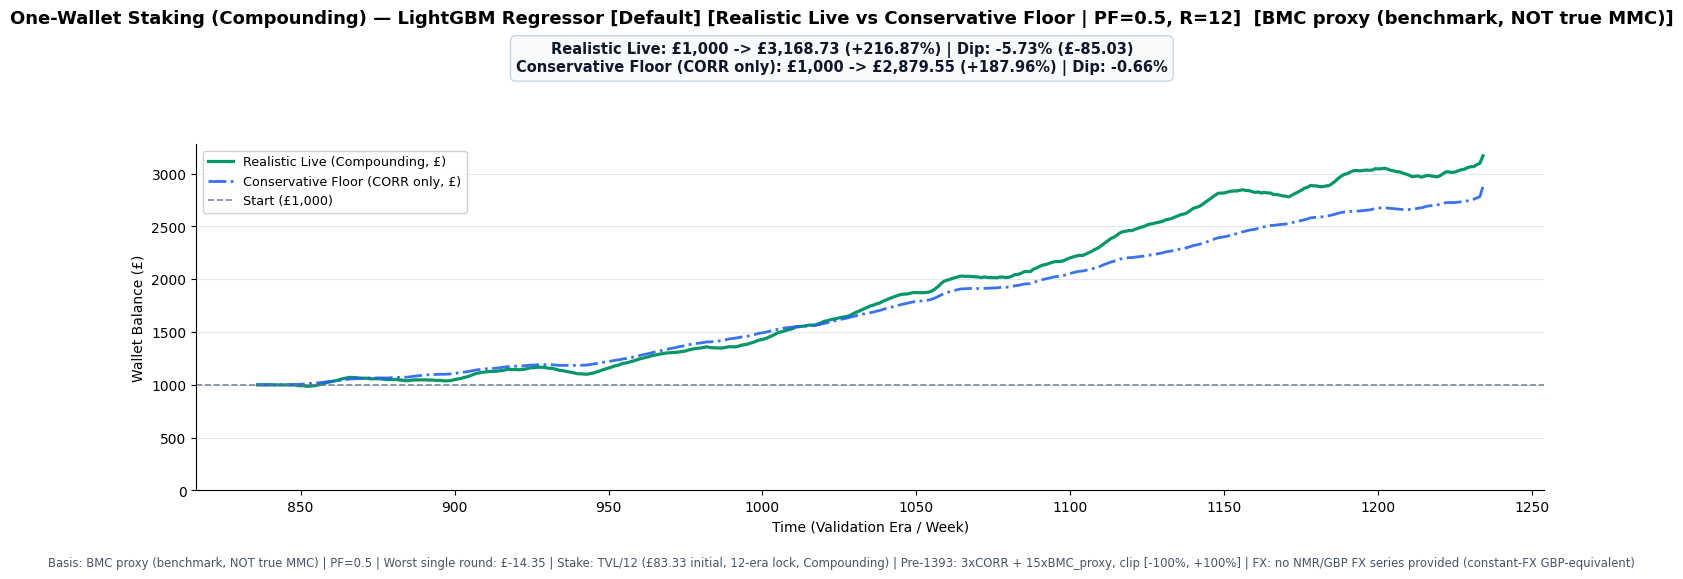

LightGBM Regressor [Default] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £3,168.73 (+216.87%, Dip -5.73%) | Conservative Floor (CORR only, PF=0.5, R=12): £2,879.55 (+187.96%, Dip -0.66%) | Basis: BMC proxy (benchmark, NOT true MMC)


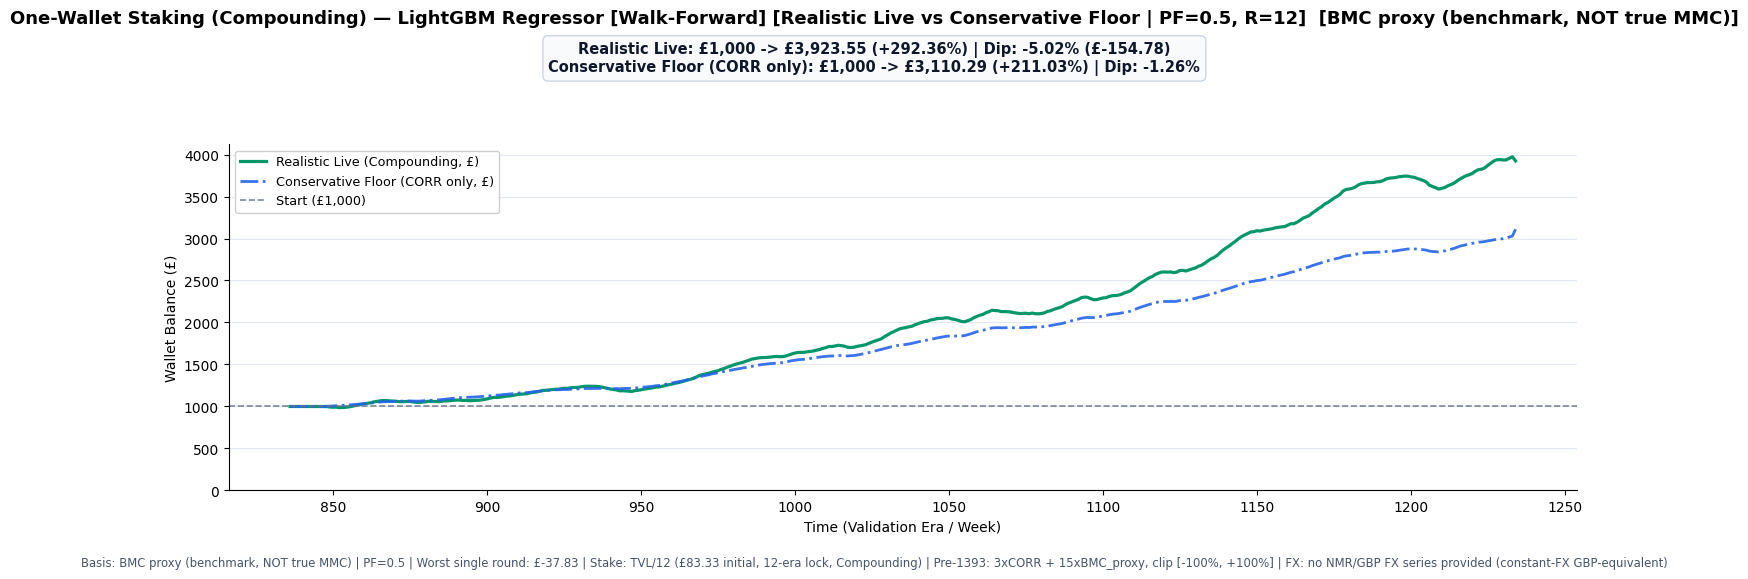

LightGBM Regressor [Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £3,923.55 (+292.36%, Dip -5.02%) | Conservative Floor (CORR only, PF=0.5, R=12): £3,110.29 (+211.03%, Dip -1.26%) | Basis: BMC proxy (benchmark, NOT true MMC)


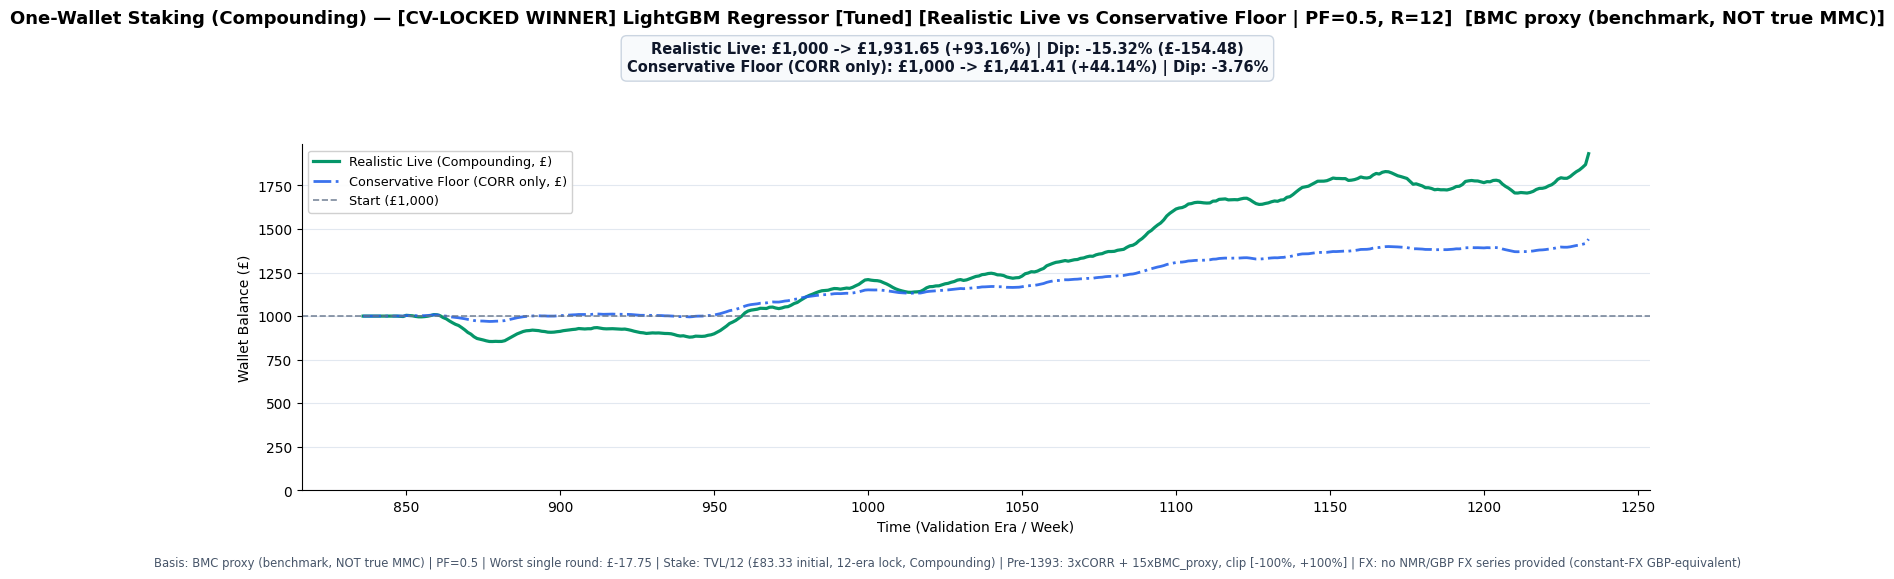

[CV-LOCKED WINNER] LightGBM Regressor [Tuned] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,931.65 (+93.16%, Dip -15.32%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,441.41 (+44.14%, Dip -3.76%) | Basis: BMC proxy (benchmark, NOT true MMC)


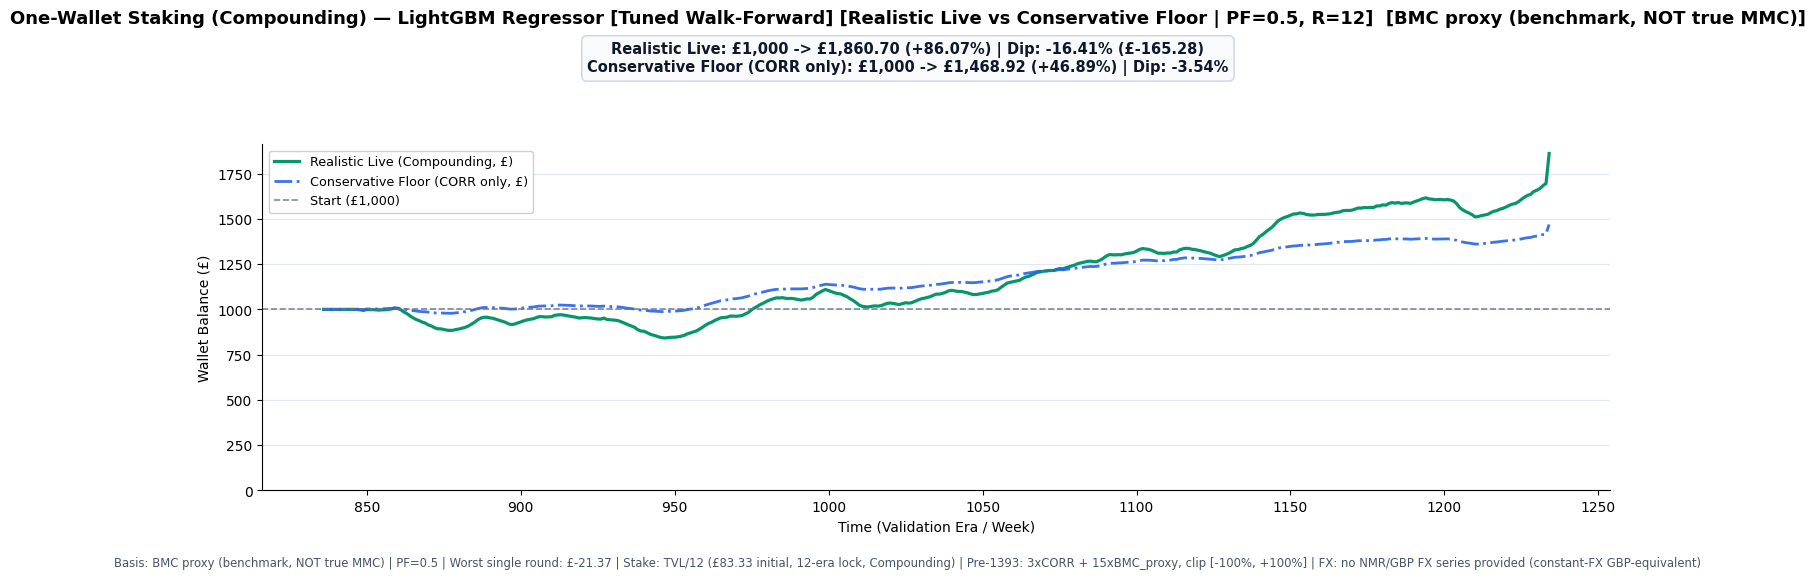

LightGBM Regressor [Tuned Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,860.70 (+86.07%, Dip -16.41%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,468.92 (+46.89%, Dip -3.54%) | Basis: BMC proxy (benchmark, NOT true MMC)
Dual-Scenario Realistic Live Staking Table (Conservative Floor vs. Realistic Live):


,variant,conservative_end_gbp,conservative_return_pct,conservative_worst_dip_pct,conservative_mc_p_profit_pct,realistic_live_end_gbp,realistic_live_return_pct,realistic_live_worst_dip_pct,realistic_live_mc_p_profit_pct,realistic_live_mc_median_gbp,payout_factor,bmc_haircut,concurrent_rounds
0,LightGBM Regressor [Default],2879.55,187.96,-0.66,100.0,3168.73,216.87,-5.73,100.0,3280.62,0.5,0.5,12
1,LightGBM Regressor [Walk-Forward],3110.29,211.03,-1.26,100.0,3923.55,292.36,-5.02,100.0,4013.12,0.5,0.5,12
2,LightGBM Regressor [Tuned],1441.41,44.14,-3.76,100.0,1931.65,93.16,-15.32,99.4,1988.98,0.5,0.5,12
3,LightGBM Regressor [Tuned Walk-Forward],1468.92,46.89,-3.54,100.0,1860.70,86.07,-16.41,99.0,1894.46,0.5,0.5,12


4160

In [17]:
val_mmc_df = val_diag_meta.assign(**{TARGET_COL: y_validation.to_numpy(dtype=np.float32)})
staking_basis_label = v6_contrib_info['basis_label']
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
print(f"Active Staking Basis: {staking_basis_label}")
print(f"  -> Reason: {v6_contrib_info['reason']}")

stake_pnl_by_variant = {}
variant_era_mmc_by_variant = {}
live_scenarios_by_variant = {}
staking_summary_rows = []
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    variant_era_corrs = model_results[variant_name]['validation_era_corrs']
    variant_era_contrib = compute_per_era_mmc(
        val_mmc_df,
        model_results[variant_name]['validation_preds'],
        meta_model_path=v6_contrib_info['meta_model_path'],
        benchmark_path=v6_contrib_info['benchmark_path'],
        is_benchmark_proxy=staking_is_proxy,
        era_col=ERA_COL,
        target_col=TARGET_COL,
    )
    variant_era_mmc_by_variant[variant_name] = variant_era_contrib

    live_scenarios_by_variant[variant_name] = simulate_live_staking_scenarios(
        variant_era_corrs,
        per_era_mmc=variant_era_contrib,
        mmc_is_proxy=staking_is_proxy,
        total_capital=1000.0,
        settlement_rounds=12,
        weekly_concurrent_rounds=12,
        conservative_payout_factor=0.5,
        live_payout_factor=0.5,
        bmc_proxy_haircut=0.5,
        n_sims=500,
        block_size=12,
        random_state=random_state,
        title=variant_name,
        era_dates=val_era_dates,
    )

    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    pnl_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_stake_pnl_dashboard.png'
        if save_results
        else None
    )
    haircutted_contrib = (
        pd.Series(variant_era_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if variant_era_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    stake_pnl_by_variant[variant_name] = plot_stake_pnl_dashboard(
        variant_era_corrs,
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        conservative_pnl=live_scenarios_by_variant[variant_name]['conservative_floor']['pnl'],
        title=f'{title_label} [Realistic Live vs Conservative Floor | PF=0.5, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        era_dates=val_era_dates,
        save_path=pnl_save_path,
    )

    v_pnl = stake_pnl_by_variant[variant_name]
    c_pnl = live_scenarios_by_variant[variant_name]['conservative_floor']['pnl']
    mean_contrib = float(variant_era_contrib.mean()) if variant_era_contrib is not None and len(variant_era_contrib) > 0 else np.nan
    contrib_col_name = 'validation_bmc_proxy' if staking_is_proxy else 'validation_true_mmc'
    staking_summary_rows.append({
        'variant': variant_name,
        'staking_basis': v_pnl['score_basis'],
        'staking_mode': 'One-Wallet (Compounding, PF=0.5, R=12)',
        'validation_corr': round(float(variant_era_corrs.mean()), 4),
        contrib_col_name: round(mean_contrib, 4) if np.isfinite(mean_contrib) else np.nan,
        'start_capital': round(float(v_pnl['start_capital']), 2),
        'end_capital': round(float(v_pnl['end_capital']), 2),
        'total_return_pct': round(float(v_pnl['total_return_pct']), 2),
        'worst_dip_pct': round(float(v_pnl['money_drawdown_pct']), 2),
        'worst_dip_gbp': round(float(v_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(v_pnl['worst_round_gbp']), 2),
    })
    print(
        f"{title_label} | Realistic Live (PF=0.5, 0.5x BMC, R=12): £{v_pnl['end_capital']:,.2f} ({v_pnl['total_return_pct']:+.2f}%, Dip {v_pnl['money_drawdown_pct']:.2f}%) | "
        f"Conservative Floor (CORR only, PF=0.5, R=12): £{c_pnl['end_capital']:,.2f} ({c_pnl['total_return_pct']:+.2f}%, Dip {c_pnl['money_drawdown_pct']:.2f}%) | "
        f"Basis: {v_pnl['score_basis']}"
    )

staking_comparison_df = pd.DataFrame(staking_summary_rows)
live_staking_scenarios_df = build_live_staking_scenarios_df(live_scenarios_by_variant)
comparison_df['staking_basis'] = comparison_df['variant'].map(
    staking_comparison_df.set_index('variant')['staking_basis']
)
if staking_is_proxy:
    comparison_df['validation_bmc_proxy'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_bmc_proxy']
    )
elif v6_contrib_info['basis_kind'] == 'true_mmc':
    comparison_df['validation_true_mmc'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_true_mmc']
    )
display_compact_dataframe(
    live_staking_scenarios_df,
    title='Dual-Scenario Realistic Live Staking Table (Conservative Floor vs. Realistic Live):',
)
best_stake_pnl = stake_pnl_by_variant[best_variant_name]
del val_mmc_df, val_diag_meta
gc.collect()

### Monte Carlo Block-Bootstrap Risk Analysis (£)

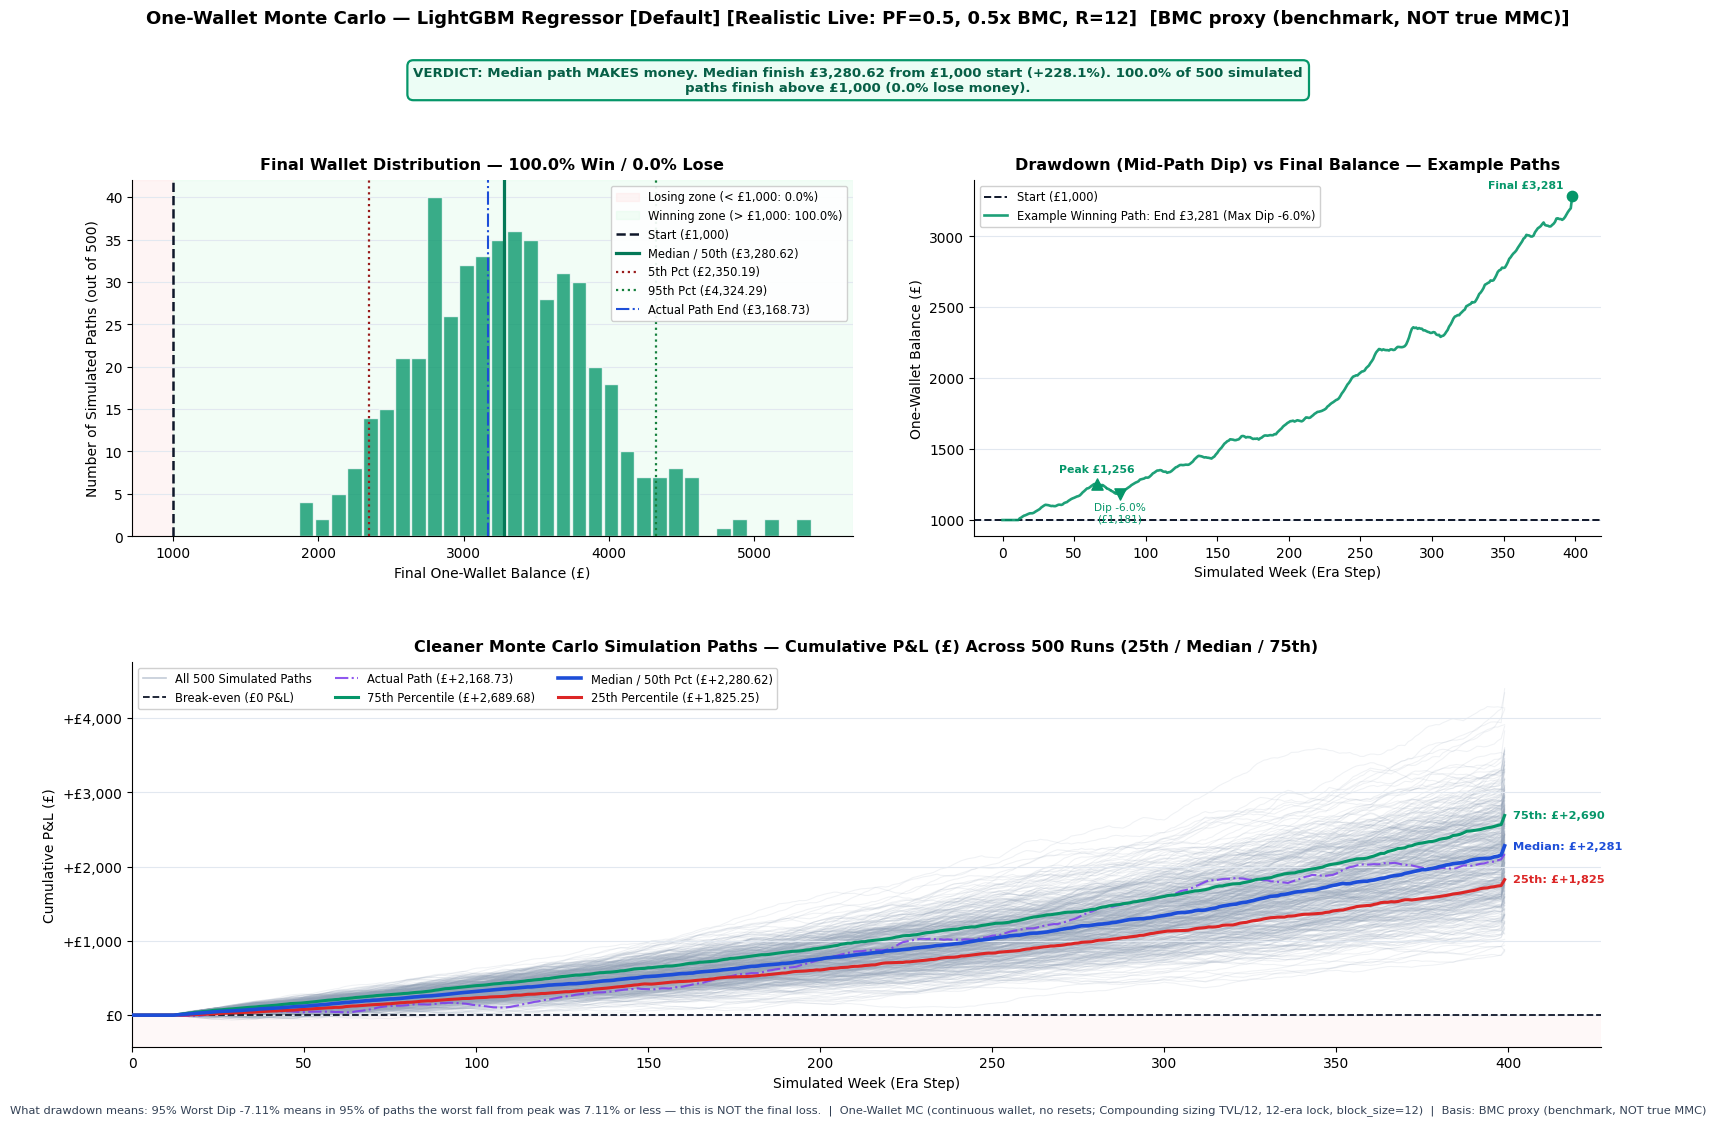

LightGBM Regressor [Default] — VERDICT: Median path MAKES money. Median finish £3,280.62 from £1,000 start (+228.1%). 100.0% of 500 simulated paths finish above £1,000 (0.0% lose money).

How to read Drawdown vs Final Balance (Plain English):
  • Drawdown is the biggest peak-to-trough dip DURING the journey — NOT your final profit or loss.
  • Worked example (Winning path with a drawdown): Start £1,000 -> rises to £1,200 peak -> dips to £1,100 (-8.3% drawdown from peak) -> recovers to £1,300. You still finish +£300 ABOVE £1,000 despite the dip.
  • Worked example (Losing path with a small drawdown): Start £1,000 -> drifts down to £955 (-4.5% dip) and ends at £984.81. A small drawdown still finishes BELOW £1,000 if it never recovers.
  • Median (50th) vs 95th percentile are DIFFERENT paths: Median = typical path; 95th = lucky top 5% of paths.
  • One-Wallet MC: Simulates ONE continuous wallet from start to finish over the full validation period with no resets.
  • Within-Window MC: Simu

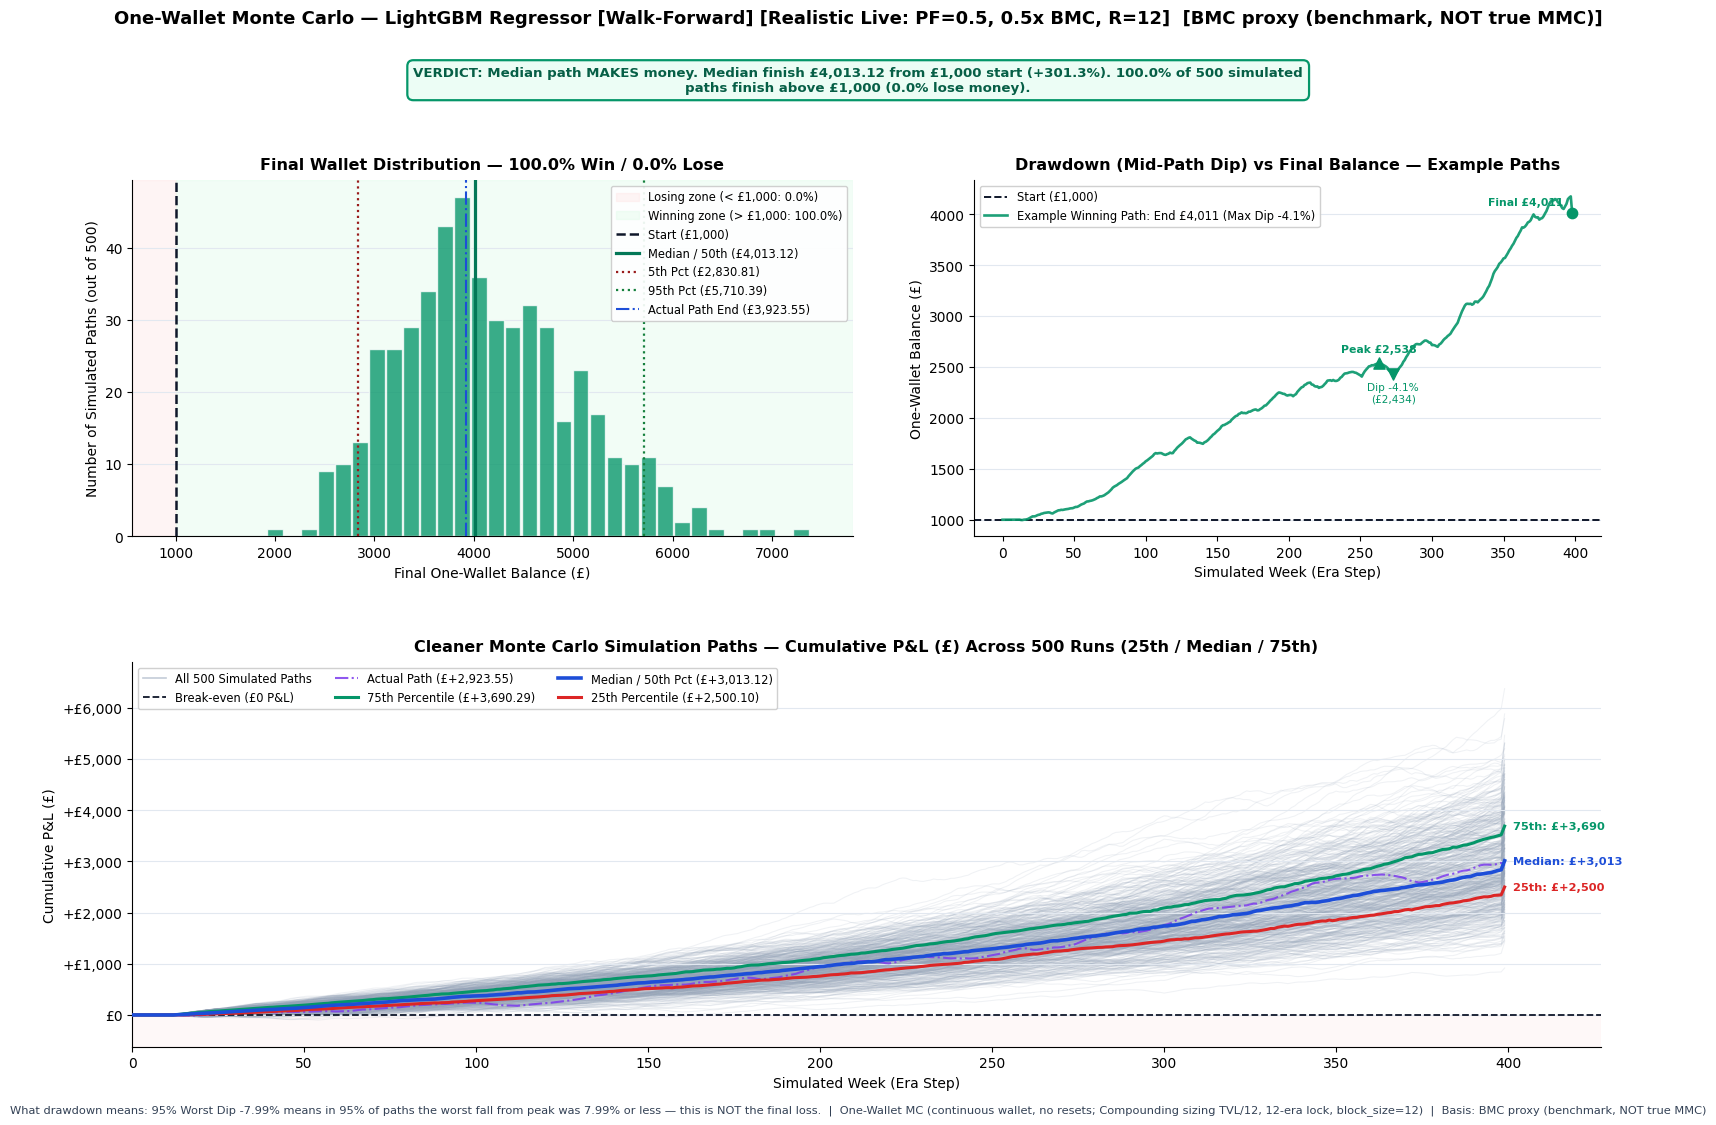

LightGBM Regressor [Walk-Forward] — VERDICT: Median path MAKES money. Median finish £4,013.12 from £1,000 start (+301.3%). 100.0% of 500 simulated paths finish above £1,000 (0.0% lose money).

LightGBM Regressor [Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 100.0% (0.0% lose) | Median (50th): £4,013.12 (+301.3%) | 5th Pct: £2,830.81 | 95th Pct: £5,710.39 | 95% Worst Dip: -7.99% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -7.99% means in 95% of paths the worst fall from peak was 7.99% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=100.0% | Median=£3,157.69 | 95% Worst Dip=-1.27%


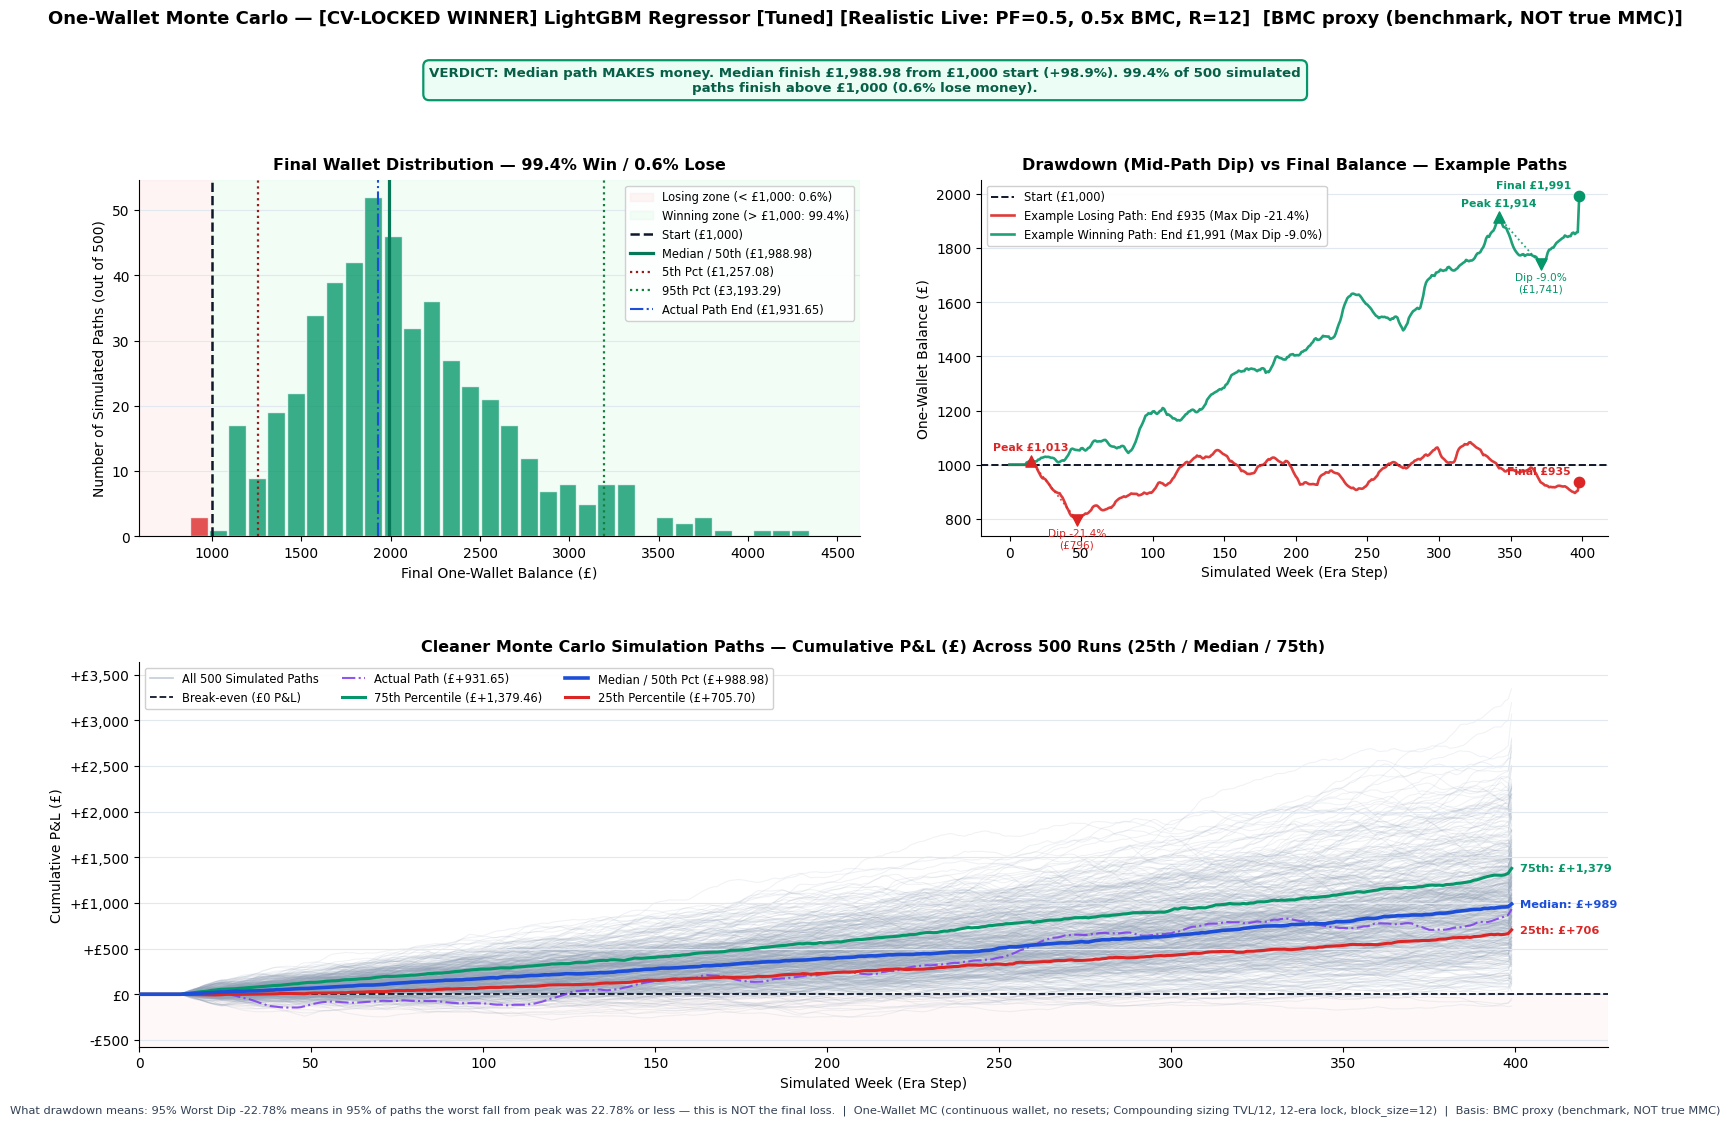

[CV-LOCKED WINNER] LightGBM Regressor [Tuned] — VERDICT: Median path MAKES money. Median finish £1,988.98 from £1,000 start (+98.9%). 99.4% of 500 simulated paths finish above £1,000 (0.6% lose money).

[CV-LOCKED WINNER] LightGBM Regressor [Tuned] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 99.4% (0.6% lose) | Median (50th): £1,988.98 (+98.9%) | 5th Pct: £1,257.08 | 95th Pct: £3,193.29 | 95% Worst Dip: -22.78% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -22.78% means in 95% of paths the worst fall from peak was 22.78% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=100.0% | Median=£1,452.58 | 95% Worst Dip=-5.79%


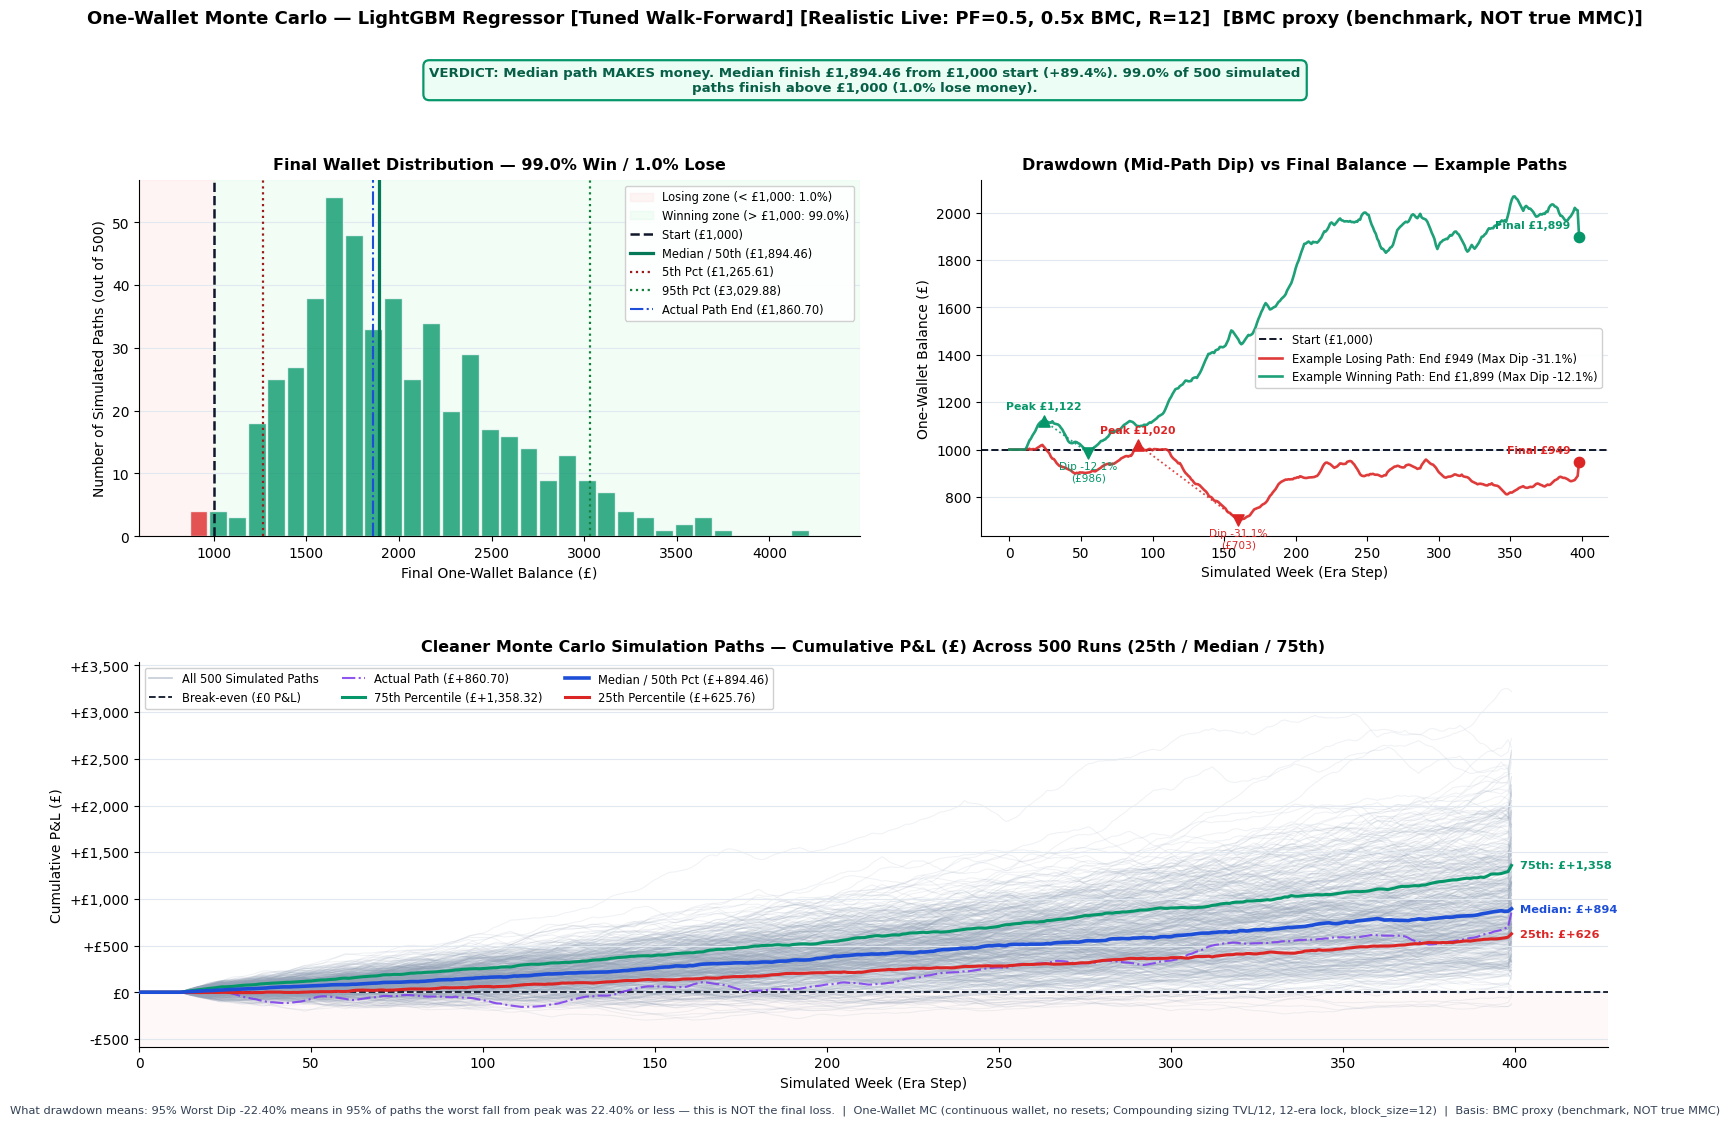

LightGBM Regressor [Tuned Walk-Forward] — VERDICT: Median path MAKES money. Median finish £1,894.46 from £1,000 start (+89.4%). 99.0% of 500 simulated paths finish above £1,000 (1.0% lose money).

LightGBM Regressor [Tuned Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 99.0% (1.0% lose) | Median (50th): £1,894.46 (+89.4%) | 5th Pct: £1,265.61 | 95th Pct: £3,029.88 | 95% Worst Dip: -22.40% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -22.40% means in 95% of paths the worst fall from peak was 22.40% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=100.0% | Median=£1,469.30 | 95% Worst Dip=-5.53%


46732

In [18]:
mc_risk_by_variant = {}
explainer_printed = False
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    mc_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_monte_carlo_pnl.png'
        if save_results
        else None
    )
    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    raw_contrib = variant_era_mmc_by_variant.get(variant_name)
    haircutted_contrib = (
        pd.Series(raw_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if raw_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    v_mc = plot_stake_pnl_monte_carlo(
        model_results[variant_name]['validation_era_corrs'],
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        title=f'{title_label} [Realistic Live: PF=0.5, 0.5x BMC, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        n_sims=500,
        block_size=12,
        random_state=random_state,
        era_dates=val_era_dates,
        save_path=mc_save_path,
        retain_paths=False,
    )
    mc_risk_by_variant[variant_name] = v_mc
    c_mc = live_scenarios_by_variant[variant_name]['conservative_floor']['mc']
    print('=' * 100)
    print(f"{title_label} — {v_mc['mc_verdict_text']}")
    if not explainer_printed:
        print()
        print(v_mc['mc_explainer_text'])
        explainer_printed = True
    print()
    print(v_mc['mc_summary_line'])
    print(f"  -> {v_mc['mc_drawdown_explanation_line']}")
    print(
        f"  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)={c_mc['mc_prob_profit_pct']:.1f}% | "
        f"Median=£{c_mc['mc_median_final_stake']:,.2f} | 95% Worst Dip={c_mc['mc_p95_money_drawdown_pct']:.2f}%"
    )
    print('=' * 100)
gc.collect()

### Cumulative & Rolling 20-Era Validation CORR

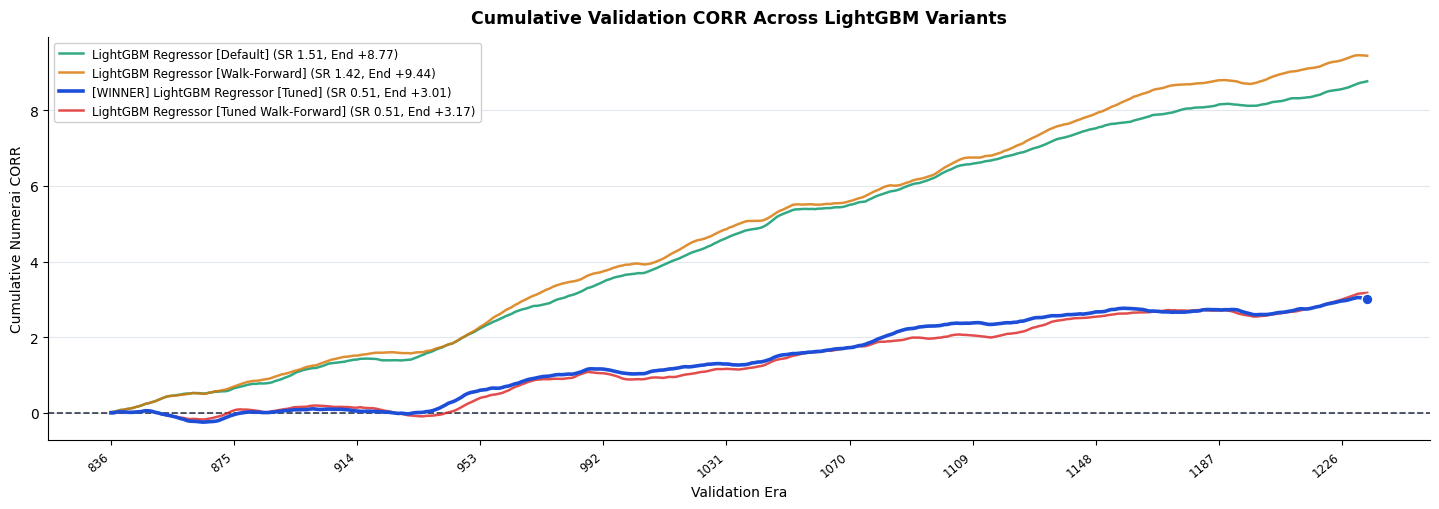

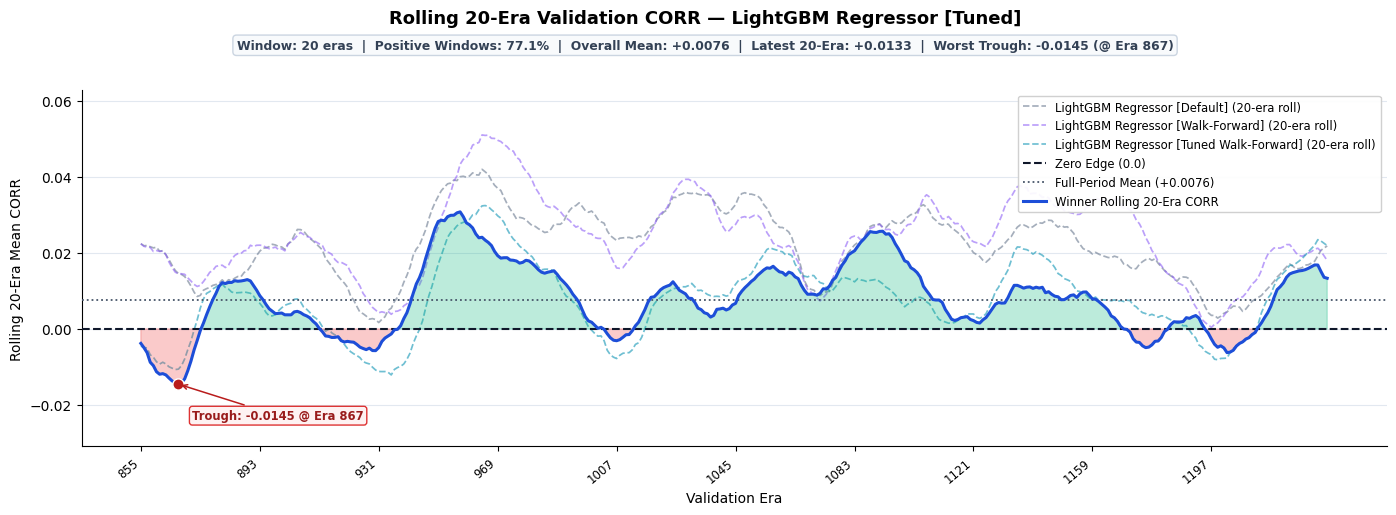

In [19]:
cum_corr_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_cumulative_validation_corr.png'
    if save_results
    else None
)
cumulative_corr_df = plot_cumulative_validation_corr(
    model_results,
    best_variant_name=best_variant_name,
    title='Cumulative Validation CORR Across LightGBM Variants',
    save_path=cum_corr_save_path,
)

secondary_era_corrs = {
    v_name: v_res['validation_era_corrs']
    for v_name, v_res in model_results.items()
    if v_name != best_variant_name
}
rolling_corr_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_rolling_20era_validation_corr.png'
    if save_results
    else None
)
rolling_20era_corr = plot_rolling_validation_corr(
    best_validation_era_corrs,
    window=20,
    comparison_corrs=secondary_era_corrs,
    title=f'Rolling 20-Era Validation CORR — {best_variant_name}',
    save_path=rolling_corr_save_path,
)

## Model Diagnostics & Residual Visuals
Compact feature-neutral & error diagnostics table, peak-annotated error-direction envelope, side-by-side Top-2 variants Residuals vs. Actual plot, and model-specific interpretability.

### Compact Diagnostics Table

In [20]:
diagnostics_table_df = build_diagnostics_summary_table(
    comparison_df,
    best_variant_name=best_variant_name,
)
display_compact_dataframe(
    diagnostics_table_df,
    title='Model Diagnostics Table (Feature Exposure, FNC, MAE, Forecast Bias & Hit Rate):',
)

Model Diagnostics Table (Feature Exposure, FNC, MAE, Forecast Bias & Hit Rate):


,variant,feature_exposure,validation_fnc,validation_fnc_sharpe,validation_mae,forecast_bias,directional_hit_rate
0,[WINNER] LightGBM Regressor [Tuned],0.1155,NaN,NaN,0.8801,0.5000,0.5059
1,LightGBM Regressor [Default],0.0865,NaN,NaN,0.1535,0.0002,0.5124
2,LightGBM Regressor [Walk-Forward],0.0803,NaN,NaN,0.1530,0.0001,0.5147
3,LightGBM Regressor [Tuned Walk-Forward],0.1041,NaN,NaN,0.8864,0.5000,0.5063


### Error-Direction Envelope Analysis

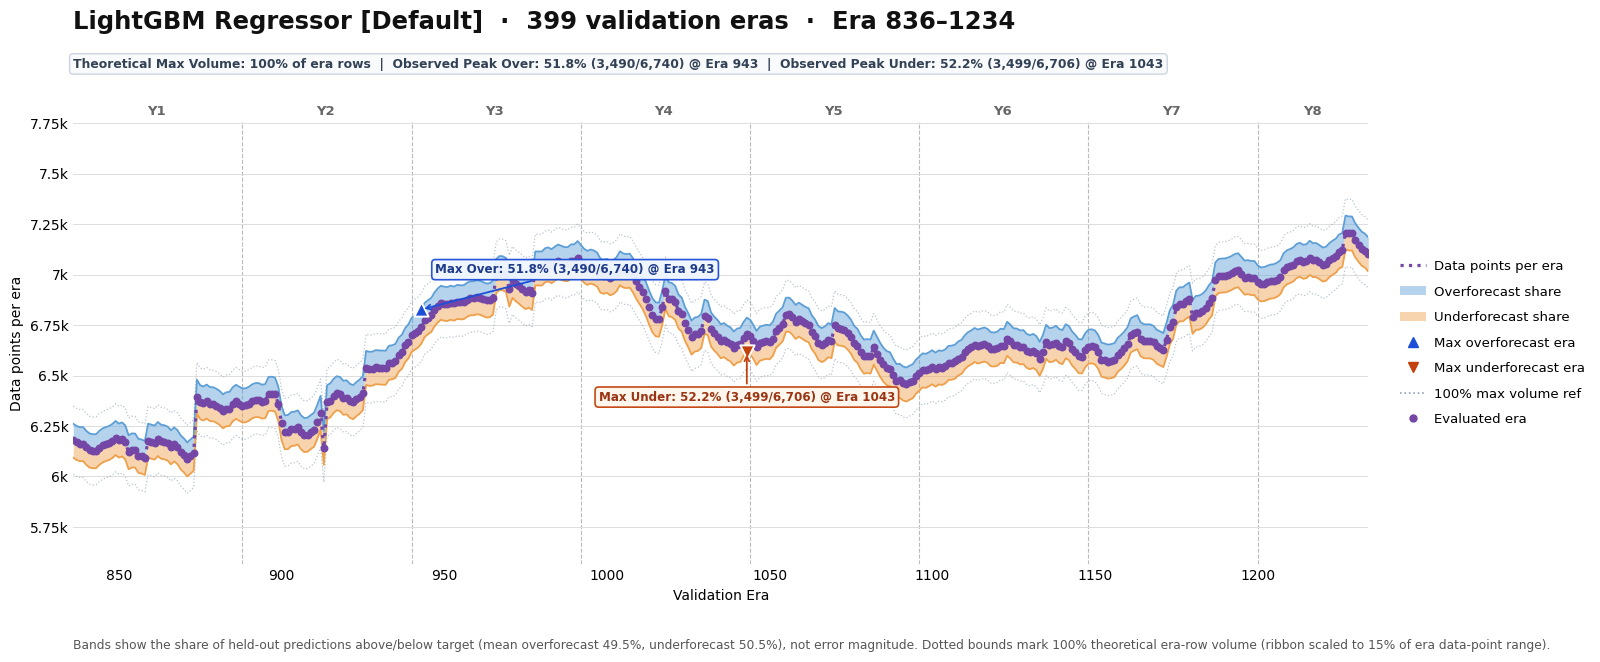

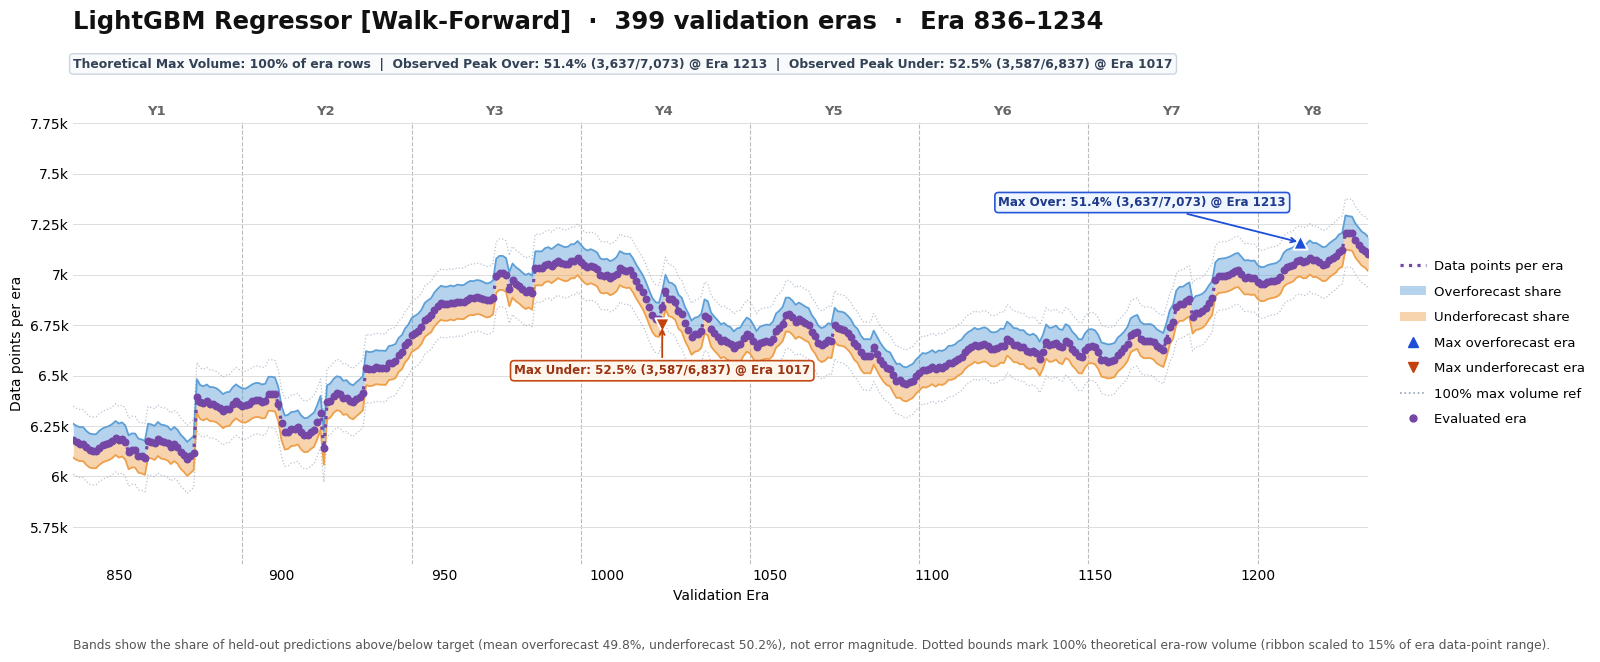

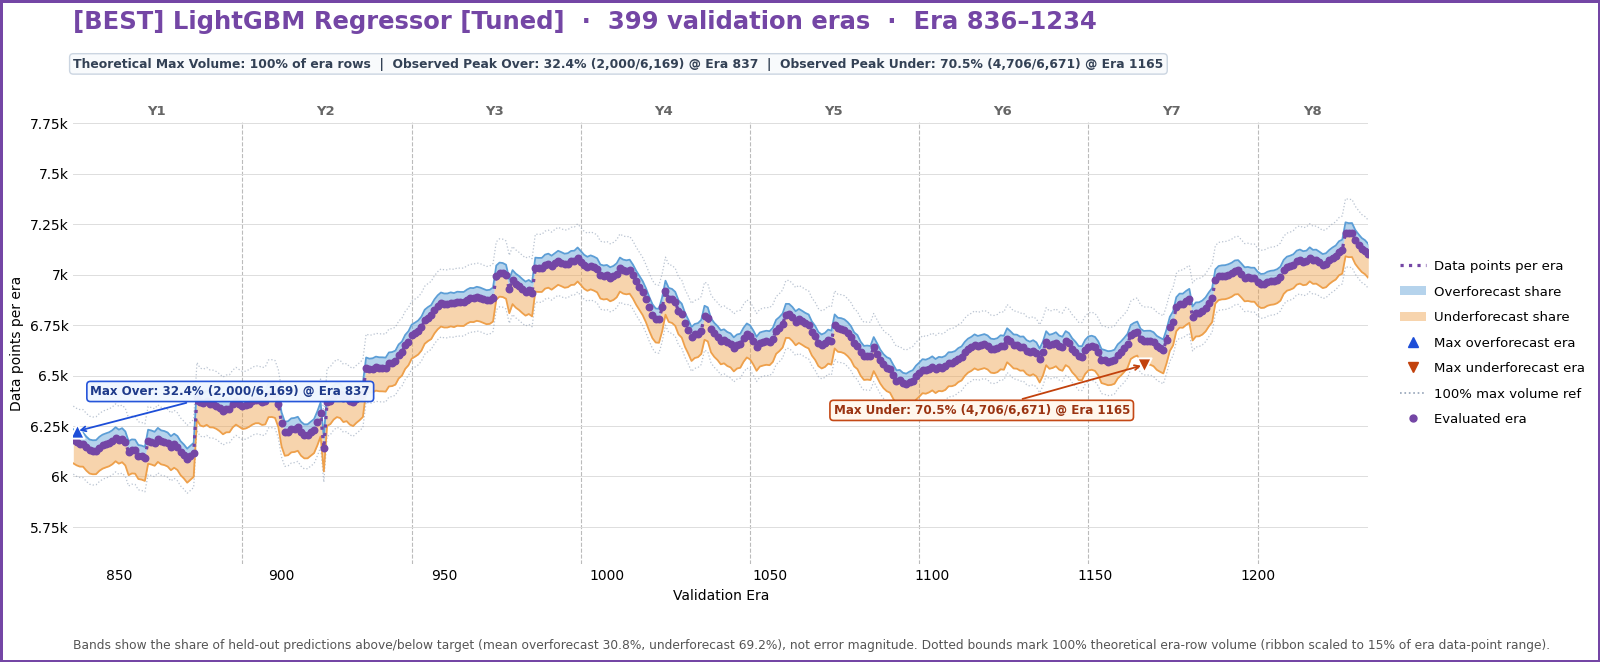

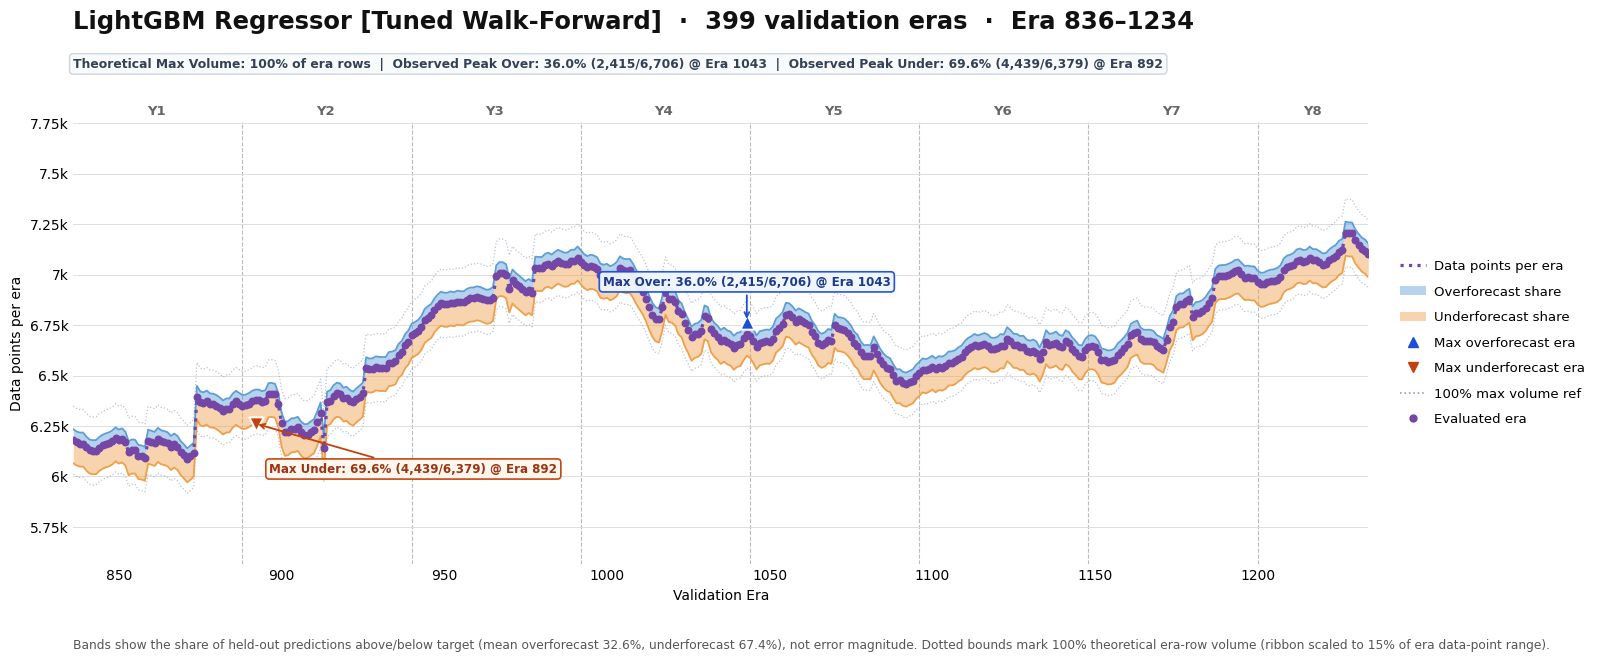

Best Model Envelope Summary (LightGBM Regressor [Tuned]):


,data_points,under_share,over_share,under_count,over_count,mae,mean_residual,is_interpolated
era,,,,,,,,
836,6180,0.683010,0.316990,4221,1959,0.887441,-0.499960,False
837,6169,0.675798,0.324202,4169,2000,0.886117,-0.499959,False
838,6163,0.677754,0.322246,4177,1986,0.882144,-0.499959,False
839,6163,0.680026,0.319974,4191,1972,0.883583,-0.499959,False
840,6144,0.682454,0.317546,4193,1951,0.882870,-0.499959,False
841,6130,0.685808,0.314192,4204,1926,0.883987,-0.499959,False
842,6126,0.684133,0.315867,4191,1935,0.885120,-0.499959,False
843,6127,0.686633,0.313367,4207,1920,0.883617,-0.499959,False
844,6143,0.684519,0.315481,4205,1938,0.883508,-0.499959,False


In [21]:
envelope_dfs = {}
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    envelope_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_error_envelope.png'
        if save_results
        else None
    )
    envelope_dfs[variant_name] = plot_era_error_envelope(
        y_validation,
        model_results[variant_name]['validation_preds'],
        validation_eras,
        title=variant_name,
        band_size=0.15,
        is_best=is_best_variant,
        save_path=envelope_save_path,
    )

envelope_df = envelope_dfs[best_variant_name]
display_compact_dataframe(
    envelope_df.head(10),
    title=f'Best Model Envelope Summary ({best_variant_name}):',
)

### Top-2 Variants Residuals vs. Actual

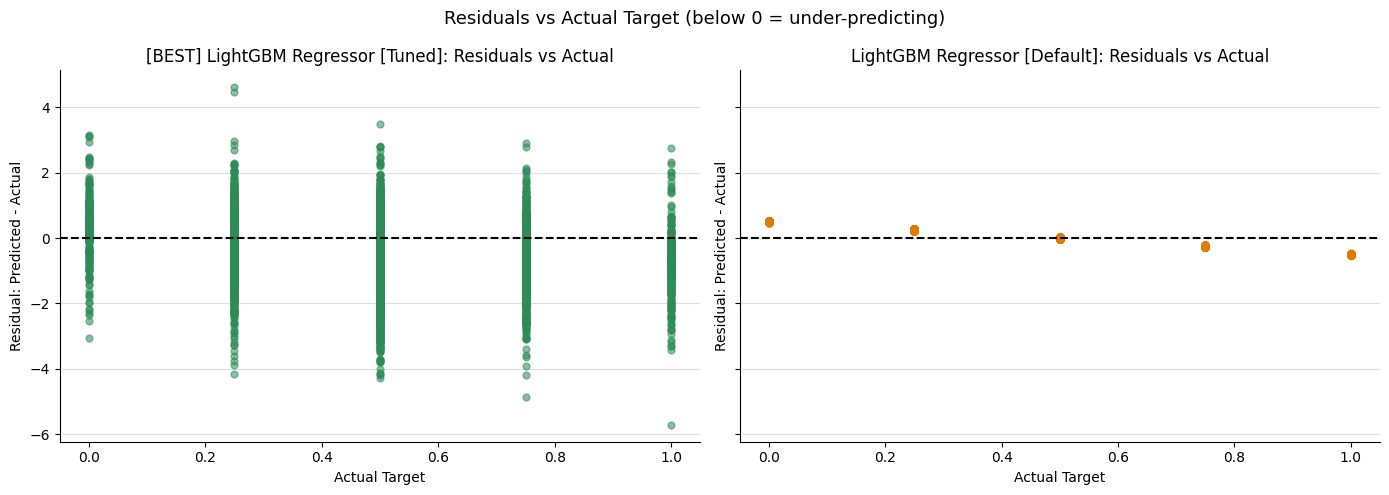

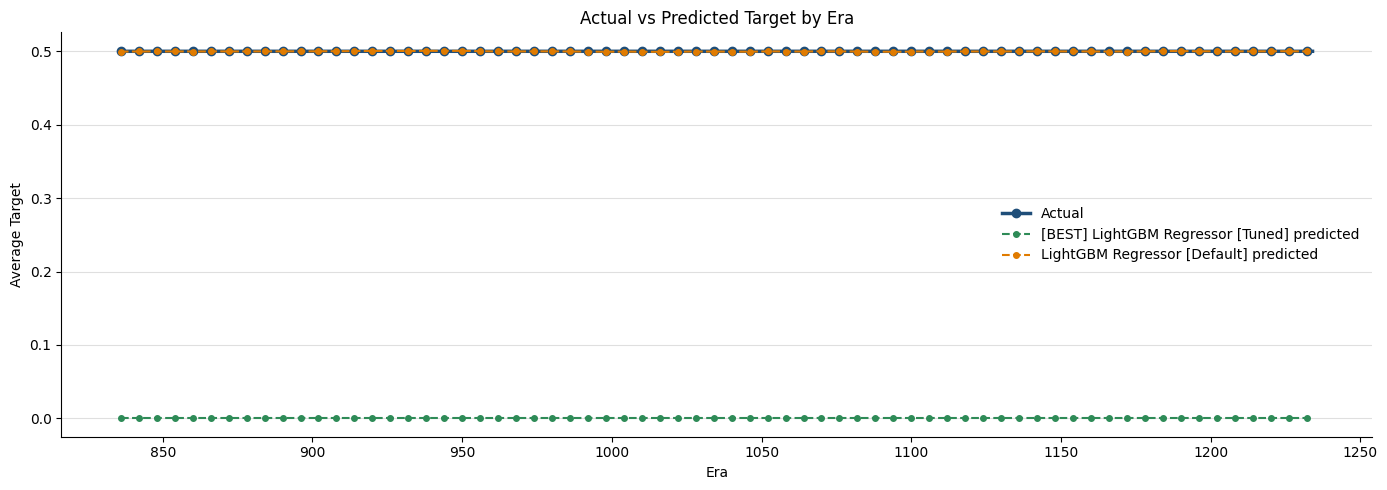

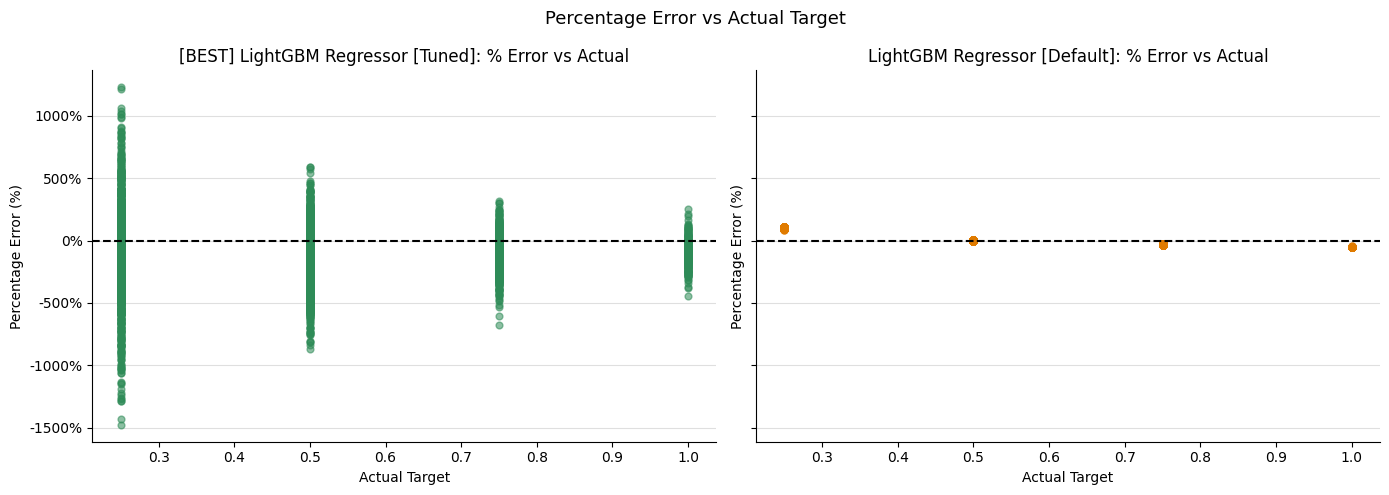

Top-2 Variants Residual Diagnostics Summary:


,variant,n_valid,mean_residual,mae,rmse,under_predict_pct,over_predict_pct
0,[BEST] LightGBM Regressor [Tuned],2660746,-0.499963,0.8801,1.1384,69.22,30.78
1,LightGBM Regressor [Default],2660746,-0.000174,0.1535,0.2237,50.46,49.54


0

In [22]:
resid_diag_save_prefix = (
    results_dir / f'{timestamp}_{experiment_name}_residual_diagnostics'
    if save_results
    else None
)
residual_diag_summary_df = plot_residual_diagnostics(
    y_validation,
    model_results,
    validation_eras,
    best_variant_name=best_variant_name,
    variant_order=comparison_df['variant'].tolist(),
    max_models=2,
    random_state=random_state,
    save_prefix=resid_diag_save_prefix,
)
display_compact_dataframe(
    residual_diag_summary_df,
    title='Top-2 Variants Residual Diagnostics Summary:',
)

numereval_summary_df = run_numereval_diagnostics(
    y_validation,
    model_results[best_variant_name]['validation_preds'],
    validation_eras,
    variant_name=best_variant_name,
    plot=False,
    verbose=False,
)
strip_validation_predictions(model_results)
del y_validation, validation_eras
gc.collect()

### Model Interpretability & Top CV Candidates

LightGBM Fitted Summary | trees=61 | selected_features=20 | boosting_type=gbdt | objective=huber


,feature,gain_importance,split_importance,train_corr
0,pca_comp_11,3.231152,14.0,0.003676
1,pca_comp_4,3.182996,18.0,0.004679
2,pca_comp_18,2.681106,23.0,0.002448
3,feature_charisma_149_ticker_exp_mean,2.679787,11.0,0.007088
4,feature_charisma_148_ticker_exp_mean,2.480068,16.0,0.006803
5,pca_comp_12,2.277903,7.0,0.011047
6,feature_constitution_29_ticker_exp_min,2.236309,13.0,0.005433
7,feature_charisma_149_ticker_exp_max,2.150866,13.0,0.004901
8,feature_constitution_29_ticker_exp_max,2.084774,11.0,0.005707
9,feature_constitution_29_ticker_exp_mean,2.040382,10.0,0.007627


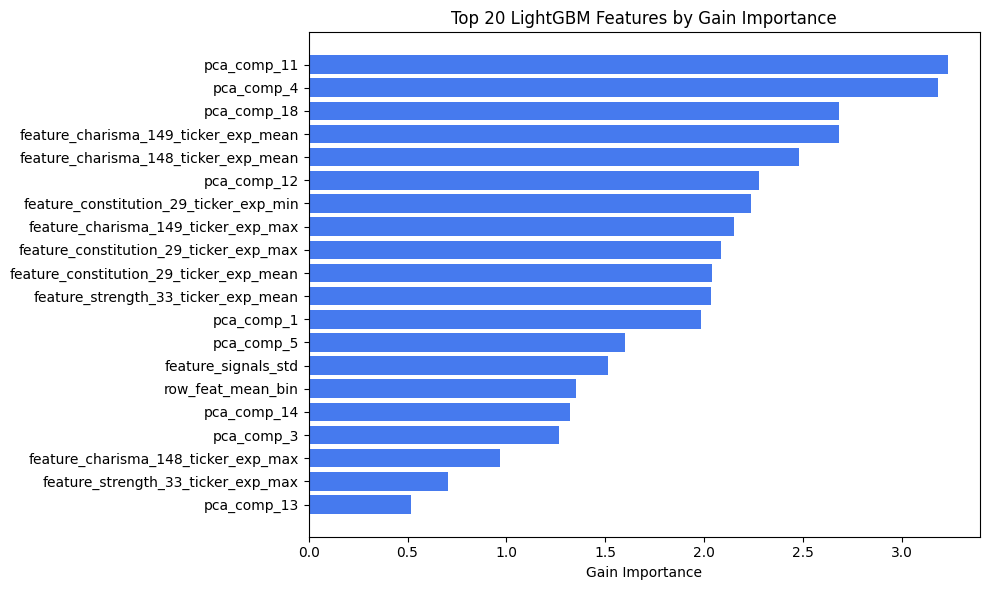

In [23]:
display_lgbm_interpretability(
    lgbm_interpretability,
    results_dir=results_dir,
    timestamp=timestamp,
    experiment_name=experiment_name,
    save_results=save_results,
)

In [24]:
display_top_cv_candidates(cv_analysis_artifacts)

Top CV candidates for LightGBM Regressor:


,candidate_id,rank_test_score,mean_test_score,score_version,end_capital,total_profit,total_return_pct,money_drawdown_pct,mean_directional_accuracy_pct,mean_accurate_pct,mean_numerai_corr,mean_sharpe,mean_positive_era_pct,mean_era_consistency_pct,mean_corr_drawdown,mean_mae,mean_fit_time,std_fit_time,mean_score_time,std_score_time,split0_test_score,std_test_score,mean_test_score_pct,mean_era_corr_std,mean_underforecast_pct,mean_extreme_underforecast_pct,mean_overforecast_pct,mean_extreme_overforecast_pct,mean_spearman,mean_forecast_bias,start_capital,max_drawdown_gbp,worst_round_gbp,abs_corr,alpha,bias_correction,correlation_method,era_weighting,extra_trees,extractor__abs_corr,extractor__basic_group_stats,extractor__correlation_method,extractor__era_dispersion_features,extractor__era_lag_scales,extractor__feature_selection_percentile,extractor__fourier_order,extractor__fourier_period_eras,extractor__include_lag_diff,extractor__include_rolling_era,extractor__missing_fill_value,extractor__pca_n_components,extractor__quantize_scope,extractor__quantize_strategy,extractor__rolling_era_windows,extractor__sequence_top_n,extractor__sparse_alpha,extractor__sparse_selector,extractor__ticker_features,extractor__ticker_lag_steps,extractor__ticker_windows,extractor__top_k,extractor__variance_threshold,extractor__year_horizon_filter,fair_c,feature_pre_filter,force_col_wise,force_row_wise,importance_type,learning_rate,linear_lambda,max_delta_step,max_depth,min_child_samples,min_child_weight,min_data_in_bin,min_split_gain,n_estimators,num_leaves,objective,path_smooth,prediction_transform,recency_decay,reg_alpha,reg_lambda,top_k,walk_forward_step_eras,walk_forward_window
0,0,1,0.003582,v1_skepta,1005.75,5.75,0.58,0.00,50.57,2.04,0.0088,0.8774,92.86,71.43,0.0060,0.8644,15.414192,0.0,4.443377,0.0,0.003582,0.0,0.36,0.0104,1.22,64.87,1.17,30.70,0.0123,0.5,1000.0,0.00,-0.28,False,1.778299,None,spearman,uniqueness_decay,False,True,std,pearson,mean|std|extreme_frac,"[1, 2, 4, 8]",100.0,3.0,26,True,False,2.0,20,global,zscore,"[4, 12]",4,0.010000,None,expanding_stats,"[1, 2]","[2, 6, 12]",NaN,NaN,"[4, 5, 6]",2.527375,True,False,True,split,0.030444,0.869987,0.672656,6,236,0.090446,17,0.024143,61,43,huber,43.012468,era_zscore,0.007396,2.655398,6.380743,20.0,20.0,expanding
1,4,2,-0.000455,v1_skepta,1003.54,3.54,0.35,-0.10,50.21,50.00,0.0054,0.4785,71.43,64.29,0.0211,0.1507,11.184880,0.0,5.933074,0.0,-0.000455,0.0,-0.05,0.0117,0.00,25.00,0.00,25.00,0.0057,0.0,1000.0,-0.99,-0.99,False,0.776399,None,None,equal_era,True,False,mean|std,pearson,mean|std|extreme_frac,"[1, 2, 4, 8]",NaN,NaN,26,True,True,era_median,10,train_fit,quantile,"[2, 6, 12]",8,0.017211,lasso,raw_lags,"[1, 2]","[4, 12]",10.0,0.05,"[1, 2, 3]",0.897397,False,False,True,gain,0.006510,0.444585,0.386265,4,235,4.156703,10,0.466377,840,30,regression,10.349397,None,0.002131,0.002841,0.368977,40.0,40.0,sliding
2,3,3,-0.002283,v1_skepta,1004.15,4.15,0.41,-0.13,50.36,1.59,0.0063,0.3812,57.14,42.86,0.0283,0.9251,10.155900,0.0,6.642268,0.0,-0.002283,0.0,-0.23,0.0172,0.97,66.87,0.94,29.63,0.0062,0.5,1000.0,-1.32,-0.91,False,1.349591,None,None,equal_era,False,True,mean|std|skew,pearson,mean,"[1, 2, 4]",NaN,2.0,52,False,True,0.0,20,global,quantile,"[2, 6, 12]",4,0.005880,elasticnet,rolling_rank,"[1, 2, 4]","[2, 6, 12]",NaN,0.02,"[7, 8, 9]",2.931490,True,False,False,split,0.021459,2.405708,0.033781,5,153,0.360900,12,0.065938,771,54,huber,3.193982,era_zscore,0.011841,0.171331,1.302721,NaN,40.0,expanding
3,1,4,-1.000000,v1_skepta,1000.00,0.00,0.00,0.00,0.00,5.00,0.0000,0.0000,0.00,0.00,0.0000,0.5000,156.921537,0.0,3.442910,0.0,-1.000000,0.0,-100.00,0.0000,0.00,0.00,0.00,95.00,0.0000,-0.5,1000.0,0.00,0.00,True,1.911356,None,numerai_mean,recency_exp,True,False,skew,numerai_mean,extreme_frac,"[2, 4, 8]",75.0,2.0,52,False,True,0.0,40,train_fit,zscore,"[4, 8, 16]",8,0.010000,None,rolling_mean|momentum_diff|rolling_rank,"[1, 2, 4]","[4, 12]",10.0,NaN,None,1.115530,False,False,False,split,0.019954,1.183591,1.138348,6

Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride12_lightgbm_target_bayes/20261125_213008_numerai_v6.0_all_eras_stride12_lightgbm_bayes_cv.csv


## AFML Backtest Visual Story
2×2 statistical credibility dashboard for the Train-CV-Locked Winner (**PSR/DSR vs. 95%**, **Observed Eras vs. MinTRL**, **Underwater / Time-Underwater Curve**, and **HHI Concentration & Regime Health**) followed by the compact AFML reference table.

### Statistical Credibility & Regime Dashboard

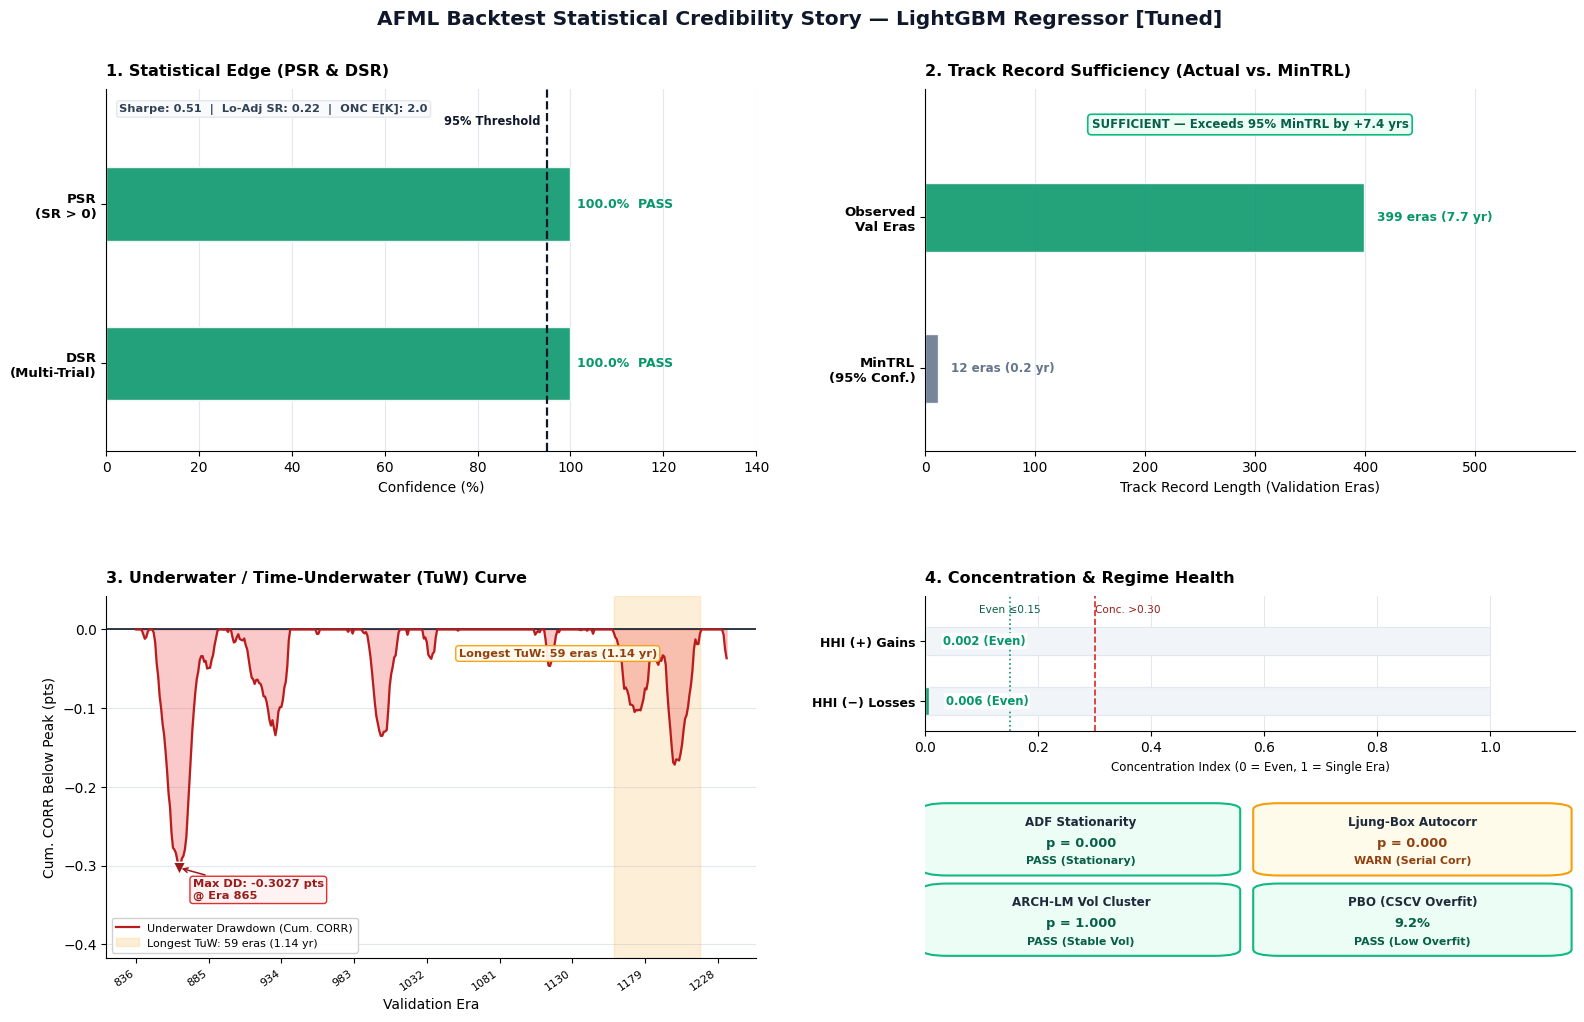

In [25]:
afml_diagnostics_df = build_afml_diagnostics_df(
    model_results,
    cv_trial_stats_by_baseline=cv_analysis_artifacts['trial_stats'],
    random_state=random_state,
)

winner_afml_matches = afml_diagnostics_df.loc[afml_diagnostics_df['variant'].astype(str) == str(best_variant_name)]
winner_afml_row = (
    winner_afml_matches.reset_index(drop=True).loc[0].to_dict()
    if not winner_afml_matches.empty
    else afml_diagnostics_df.reset_index(drop=True).loc[0].to_dict()
)
afml_story_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_afml_backtest_story.png'
    if save_results
    else None
)
afml_story_summary = plot_afml_backtest_story(
    best_validation_era_corrs,
    winner_afml_row,
    regime_stats=model_results[best_variant_name],
    title=best_variant_name,
    save_path=afml_story_save_path,
)

### AFML Backtest Reference Table

In [26]:
compact_afml_df = build_compact_afml_reference_table(
    afml_diagnostics_df,
    best_variant_name=best_variant_name,
)
display_compact_dataframe(
    compact_afml_df,
    title='AFML Backtest Credibility Reference Table (PSR, DSR, MinTRL, PBO, TuW & HHI):',
)
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    afml_diagnostics_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_afml_diagnostics.csv', index=False)

AFML Backtest Credibility Reference Table (PSR, DSR, MinTRL, PBO, TuW & HHI):


,variant,n_eras,numerai_sharpe,lo_adjusted_sharpe,psr,dsr,min_trl_years,pbo_cscv,tuw_max_years,hhi_pos,hhi_neg,strategy_fail_prob
0,[WINNER] LightGBM Regressor [Tuned],399,0.511,0.225,1.0,1.0,0.23,0.092,1.14,0.0020,0.0063,0.0
1,LightGBM Regressor [Default],399,1.514,0.680,1.0,1.0,0.07,NaN,0.27,0.0008,0.0295,0.0
2,LightGBM Regressor [Walk-Forward],399,1.420,0.624,1.0,1.0,0.07,NaN,0.23,0.0008,0.0203,0.0
3,LightGBM Regressor [Tuned Walk-Forward],399,0.511,0.221,1.0,1.0,0.24,0.092,0.89,0.0017,0.0051,0.0


## Optional Community Companion: `numereval` (Council of Elders)
Runs `councilofelders/numereval` alongside official `numerai-tools` metrics when installed locally (skips gracefully on Kaggle if unavailable). **Note:** `numereval` uses classic Spearman diagnostics and is not the official v6.0 Unity `NCORR` / `NMMC` / staking calculation.

In [27]:
if numereval_summary_df is not None:
    print(
        f"[numereval companion — {best_variant_name}] Community Spearman diagnostics "
        "(informational alongside official numerai_tools v6.0 metrics; NOT official v6.0 NCORR/NMMC):"
    )
    display_compact_dataframe(numereval_summary_df)
else:
    run_numereval_diagnostics([], [], [], variant_name=best_variant_name, plot=False, verbose=True)

[numereval companion — LightGBM Regressor [Tuned]] Community Spearman diagnostics (informational alongside official numerai_tools v6.0 metrics; NOT official v6.0 NCORR/NMMC):


,metrics
mean,0.0089
std,0.0146
sharpe,0.6076
max_drawdown,-2.0168


## Optional Experiment Tracking (Weights & Biases)

In [28]:
if use_wandb:
    if wandb is None:
        print('Skipping W&B logging: wandb is not installed.')
    else:
        wandb_run = wandb.init(
            project=wandb_project,
            name=experiment_name,
            config={
                'data_version': data_version,
                'era_tag': era_tag,
                'model_tag': model_tag,
                'TARGET_COL': TARGET_COL,
                'feature_set': feature_set,
                'era_stride': era_stride,
                'search_mode': search_mode,
                'cv_strategy': cv_strategy,
                'n_splits': n_splits,
                'cv_split': cv_split,
                'downsample_mode': downsample_mode,
                'downsample_frac': downsample_frac,
                'val_downsample_mode': val_downsample_mode,
                'val_downsample_frac': val_downsample_frac,
                'target_horizon_eras': target_horizon_eras,
                'embargo_eras': embargo_eras,
                'eval_mode': eval_mode,
                'walk_forward_step_eras': walk_forward_step_eras,
                'walk_forward_window': walk_forward_window,
                'era_weighting': era_weighting,
                'recency_decay': recency_decay,
                'random_state': random_state,
                'n_iter': n_iter,
                'verbose': verbose,
                'n_jobs': n_jobs,
                'lgbm_n_jobs': lgbm_n_jobs,
                'error_bin_mode': error_bin_mode,
            },
        )
        log_payload = {
            'comparison_table': wandb.Table(dataframe=comparison_df),
            'search_summary_table': wandb.Table(dataframe=search_summary_df.drop(columns=['best_params'], errors='ignore')),
            'timing/prep_elapsed_s': float(prep_elapsed_s),
            'timing/train_elapsed_s': float(train_elapsed_s),
        }
        for m_name, m_cv_df in cv_analysis_artifacts['top_candidates'].items():
            m_slug = m_name.lower().replace(' ', '_')
            log_payload[f'cv_table/{m_slug}'] = wandb.Table(dataframe=m_cv_df.astype(str))
        for row in search_summary_rows:
            m_slug = row['model'].lower().replace(' ', '_')
            log_payload[f'best_cv_corr/{m_slug}'] = float(row['best_cv_corr'])
        wandb.log(log_payload)
        wandb.finish()
        print('Logged experiment tables and metrics to Weights & Biases.')
else:
    print('W&B tracking disabled (use_wandb=False).')

W&B tracking disabled (use_wandb=False).
